# Intro to this notebook

This notebook is an exact-diagonalization (ED) study of ergodicity breaking and many-body localization (MBL) in 1D spin chains. It starts by reproducing Nieuwenburg's Stark-MBL model (a tilted, disordered XXZ Heisenberg chain) at half-filling and in single-excitation sectors, using level-spacing statistics (⟨r⟩) and inverse participation ratio (IPR) to distinguish thermal/chaotic (GOE, ⟨r⟩≈0.53) from localized (Poisson, ⟨r⟩≈0.39) regimes. It then moves to the paper's own Hamiltonian — a power-law long-range Ising model with nearest-neighbor flip-flop terms — implementing reflection-symmetry block-diagonalization (to remove spurious level repulsion) and half-chain entanglement entropy as an additional, basis-independent diagnostic. The remainder of the notebook runs systematic parameter sweeps (over Ising coupling $J_z$, long-range exponent $\alpha$, disorder $W$, system size $L$, and excitation-number sector $n_\uparrow$), producing phase diagrams (⟨r⟩, IPR, entanglement entropy heatmaps) and finite-size scaling plots to map out where the system transitions between ergodic and localized phases.

# Nieuwenburg's Hamiltonian
recreating https://www.pnas.org/doi/full/10.1073/pnas.1819316116

## Half-filled case (Fig 1 in the paper)

This script is a **Exact Diagonalization (ED) numerical simulation** written in Python to study quantum chaos, thermalization, and localization in a 1D quantum spin system.

Specifically, it simulates a **1D Anisotropic Heisenberg ($XXZ$) spin-1/2 chain** subjected to both a **linear potential tilt** ($F$) and **random magnetic disorder** ($W$). It measures two key physics diagnostic tools: the **adjacent level spacing ratio ($\langle r \rangle$)** and the **Inverse Participation Ratio (IPR)**.

---

### High-Level Physical Context

This code is designed to probe transitions between different quantum regimes:

* **Thermal / Ergodic Phase (GOE Statistics):** Chaos and thermalization occur ($\langle r \rangle \approx 0.5307$, low IPR / delocalized states).
* **Localized Phase (Poisson Statistics):** Chaos is broken via Many-Body Localization (MBL) or Stark Localization ($\langle r \rangle \approx 0.3863$, high IPR / localized states).

---

### Detailed Section-by-Section Breakdown

#### 1. Hilbert Space & Basis Construction

```python
def half_filled_basis(L): ...
def basis_index(basis): ...

```

* **Conservation Law:** Total magnetization $S^z_{\text{total}} = \sum_i S^z_i$ is conserved in the XXZ model. The code restricts calculations to the **zero-magnetization / half-filled sector** ($L/2$ up spins, $L/2$ down spins) to dramatically reduce Hilbert space dimension from $2^L$ to $\binom{L}{L/2}$.
* `half_filled_basis`: Generates combinations of $L/2$ spin-up positions using `itertools.combinations`.
* `basis_index`: Creates a hash map (dictionary) pairing each spin state tuple to its index $0, 1, \dots, \text{dim}-1$ for $O(1)$ lookups during matrix assembly.

---

#### 2. Hamiltonian Construction

```python
def build_heisenberg(L, J0=1.0, Jz=1.0, F=0.0, h=None): ...

```

Constructs the Hamiltonian matrix $\hat{H}$ in the half-filled basis. The full physical operator is:

$$\hat{H} = \sum_{j=0}^{L-2} \left[ \frac{J_0}{2} (S^+_j S^-_{j+1} + S^-_j S^+_{j+1}) + J_z S^z_j S^z_{j+1} \right] + \sum_{j=0}^{L-1} (F \cdot j + h_j) S^z_j$$

* **Diagonal Entries ($H_{n,n}$):**
* **Ising term ($J_z S^z_j S^z_{j+1}$):** Adds $J_z / 4$ if neighbor spins are parallel, or $-J_z / 4$ if antiparallel.
* **Stark/Tilt field ($F \cdot j \cdot S^z_j$):** Adds linear field potential gradient.
* **Disorder field ($h_j \cdot S^z_j$):** Adds random site potential $h_j \in [-W, W]$.


* **Off-Diagonal Entries ($H_{m,n}$):**
* **Flip-Flop term ($J_0 (S^x S^x + S^y S^y)$):** Evaluated as $\frac{J_0}{2} (S^+_i S^-_{i+1} + S^-_i S^+_{i+1})$. It swaps antiparallel adjacent spins ($\vert{}\dots \uparrow \downarrow \dots \rangle \leftrightarrow \vert{}\dots \downarrow \uparrow \dots \rangle$) with matrix element $J_0 / 2$.



---

#### 3. Spectral & Wavefunction Diagnostics

```python
def level_spacing_ratio(evals): ...

```

* **Level Spacing Ratio ($r$):**
Calculates $r_i = \frac{\min(s_i, s_{i+1})}{\max(s_i, s_{i+1})}$ where $s_i = E_{i+1} - E_i$.
* **Poisson (Localized):** $\langle r \rangle \approx 0.3863$ (uncorrelated energy levels crossing each other).
* **GOE (Gaussian Orthogonal Ensemble / Chaotic):** $\langle r \rangle \approx 0.5307$ (level repulsion prevents energy level crossing).



```python
def compute_IPR(evecs): ...

```

* **Inverse Participation Ratio (IPR):**

$$\text{IPR}_n = \sum_{i=1}^{\text{dim}} \vert{}\psi_n(i)\vert{}^4$$


* Measures spatial localization of eigenstates in the computational basis.
* **Delocalized state:** $\text{IPR} \sim 1/\text{dim} \to 0$ (probability spread evenly across all states).
* **Localized state:** $\text{IPR} \sim \mathcal{O}(1)$ (probability concentrated in very few basis states).



```python
def middle_spectrum(evals, evecs, frac=0.2): ...

```

* Selects a central fraction (`frac`) of eigenvalues and eigenvectors around the middle of the energy spectrum. High-energy states at the ground-state/top edges often show non-generic boundary physics; the mid-spectrum states best capture infinite-temperature thermalization properties.

---

#### 4. Disorder Averaging & Execution Loop

```python
def analyze_realization(...): ...
def disorder_average(...): ...

```

1. Generates random disorder field vector $h_i \in [-W, W]$.
2. Builds and diagonalizes $\hat{H}$ using `scipy.linalg.eigh` (optimized for dense Hermitian/symmetric matrices).
3. Extracts middle spectrum states and computes $r$ and $\text{IPR}$.
4. Runs `realizations` iterations (e.g., $120$ times) and returns sample averages and standard deviations.

---

#### 5. Parameter Sweeps & Visualization

1. **System Size:** $L = 11$ spins $\to \binom{11}{5} = 462$ Hilbert space dimension.
2. **Field Sweep:** Varies field strength $F$ from $0$ to $3.0$ across $11$ steps with fixed weak disorder $W = 0.2$.
3. **Plots Generated:**
* **Plot 1 ($\langle r \rangle$ vs $F$):** Plots level statistics alongside benchmark horizontal lines for GOE ($0.5307$) and Poisson ($0.3863$). Tracks how increasing potential gradient $F$ drives the system from chaotic thermal behavior into **Stark Many-Body Localization**.
* **Plot 2 ($\text{Average IPR}$ vs $F$):** Shows wavefunctions localizing in real space as $F$ increases (IPR increases away from zero).

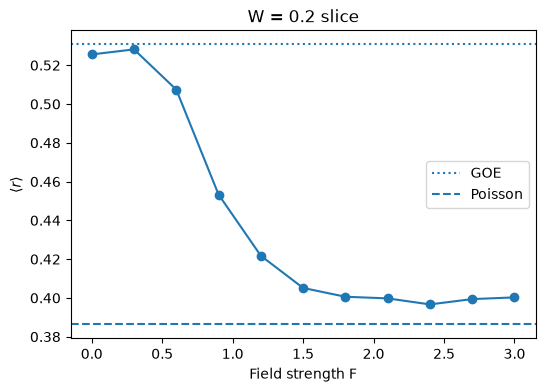

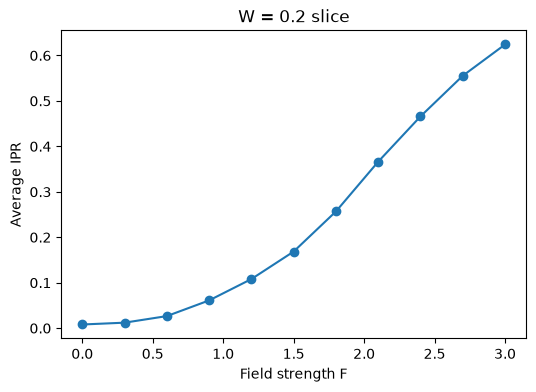

In [1]:
# ============================================================
# Imports
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations
from scipy.linalg import eigh


# ============================================================
# Basis: half-filled sector
# ============================================================

def half_filled_basis(L):
    """
    Generate all spin configurations with L/2 up spins.
    
    State convention:
    1 = spin up
    0 = spin down
    """

    basis = []

    for ups in combinations(range(L), L//2):

        state = [0]*L

        for i in ups:
            state[i] = 1

        basis.append(tuple(state))

    return basis



def basis_index(basis):

    return {
        state:i for i,state in enumerate(basis)
    }



# ============================================================
# Heisenberg Hamiltonian
# ============================================================
def build_heisenberg(L, J0=1.0, Jz=1.0, F=0.0, h=None):
    """
    Anisotropic Heisenberg (XXZ) Hamiltonian with tilt:

    H = sum_j [ J0 (SxSx + SySy) + Jz SzSz ]_{j,j+1}
        + sum_j F*j*Sz_j
        + sum_j h_j*Sz_j

    Restricted to half-filled sector.

    Parameters
    ----------
    L  : system size
    J0 : XY (flip-flop) coupling
    Jz : Ising (ZZ) coupling
    F  : linear tilt field strength
    h  : array of random on-site fields (optional)

    Returns
    -------
    H, basis
    """

    basis = half_filled_basis(L)
    index = basis_index(basis)

    dim = len(basis)

    H = np.zeros((dim,dim),dtype=float)


    for n,state in enumerate(basis):


        # -----------------------------
        # on-site Sz terms: tilt + random field
        # -----------------------------

        for i in range(L):

            sz = 0.5 if state[i]==1 else -0.5

            # linear tilt field F*j*Sz_j
            H[n,n] += F*i*sz

            # random field h_j*Sz_j
            if h is not None:
                H[n,n] += h[i]*sz



        # -----------------------------
        # nearest-neighbor XXZ terms
        # -----------------------------

        for i in range(L-1):

            si = 1 if state[i]==1 else -1
            sj = 1 if state[i+1]==1 else -1


            # Jz SzSz contribution

            H[n,n] += Jz*0.25*si*sj



            # J0 (SxSx + SySy)
            # flips neighboring opposite spins

            if state[i] != state[i+1]:


                new_state = list(state)

                new_state[i],new_state[i+1] = (
                    new_state[i+1],
                    new_state[i]
                )

                new_state = tuple(new_state)

                m = index[new_state]


                H[m,n] += J0*0.5


    return H,basis



# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H):

    evals,evecs = eigh(H)

    return evals,evecs



# ============================================================
# Select middle of spectrum
# ============================================================

def middle_spectrum(evals,evecs,frac=0.2):
    """
    Keep fraction of states around the middle energy.
    """

    N=len(evals)

    start=int(N*(0.5-frac/2))
    end  =int(N*(0.5+frac/2))


    return evals[start:end], evecs[:,start:end]



# ============================================================
# Level statistics
# ============================================================

def level_spacing_ratio(evals):

    evals=np.sort(evals)

    spacings=np.diff(evals)


    r=[]

    for i in range(len(spacings)-1):

        r.append(
            min(spacings[i],spacings[i+1]) /
            max(spacings[i],spacings[i+1])
        )


    return np.mean(r)



# ============================================================
# Inverse participation ratio
# ============================================================

def compute_IPR(evecs):
    """
    IPR = sum_i |psi_i|^4
    """

    ipr=[]


    for n in range(evecs.shape[1]):

        psi=evecs[:,n]

        ipr.append(
            np.sum(np.abs(psi)**4)
        )


    return np.array(ipr)



# ============================================================
# Single disorder realization
# ============================================================

def analyze_realization(L,W,J0=1.0,Jz=1.0,F=0.0,frac=0.2):
    """
    One disorder realization.

    h_i uniform[-W,W]
    """

    h=np.random.uniform(-W,W,L)


    H,basis = build_heisenberg(
        L=L,
        J0=J0,
        Jz=Jz,
        F=F,
        h=h
    )


    evals,evecs = diagonalize(H)


    evals_mid,evecs_mid = middle_spectrum(
        evals,
        evecs,
        frac
    )


    r = level_spacing_ratio(evals_mid)

    ipr = np.mean(
        compute_IPR(evecs_mid)
    )


    return r,ipr

# ============================================================
# Disorder averaging
# ============================================================

def disorder_average(
        L,
        W,
        realizations=50,
        J0=1.0,
        Jz=1.0,
        F=0.0,
        frac=1):


    r_values=[]
    ipr_values=[]


    for _ in range(realizations):

        r,ipr = analyze_realization(
            L=L,
            W=W,
            J0=J0,
            Jz=Jz,
            F=F,
            frac=frac
        )

        r_values.append(r)
        ipr_values.append(ipr)


    return (
        np.mean(r_values),
        np.std(r_values),
        np.mean(ipr_values),
        np.std(ipr_values)
    )



# ============================================================
# Example: reproduce r statistics vs disorder
# ============================================================

L=11

# W_values=np.linspace(0,7,21)
W_values=[0.2]


r_results=[]
ipr_results=[]


for W in W_values:

    r_mean,r_std,ipr_mean,ipr_std = disorder_average(
        L=L,
        W=W,
        realizations=120,
        J0=1,
        Jz=1,
        F=0.5,
        frac=1
    )


    r_results.append(r_mean)
    ipr_results.append(ipr_mean)


# ============================================================
# F sweep at fixed W=0.2
# ============================================================

F_values = np.linspace(0, 3, 11)

r_results_F = []
ipr_results_F = []

for F in F_values:

    r_mean, r_std, ipr_mean, ipr_std = disorder_average(
        L=L,
        W=0.2,
        realizations=120,
        J0=1,
        Jz=1,
        F=F,
        frac=0.5
    )

    r_results_F.append(r_mean)
    ipr_results_F.append(ipr_mean)


plt.figure(figsize=(6,4))
plt.plot(F_values, r_results_F, marker="o")
plt.axhline(0.5307, linestyle=":", label="GOE")
plt.axhline(0.3863, linestyle="--", label="Poisson")
plt.xlabel("Field strength F")
plt.ylabel(r"$\langle r\rangle$")
plt.title("W = 0.2 slice")
plt.legend()
plt.show()


plt.figure(figsize=(6,4))
plt.plot(F_values, ipr_results_F, marker="o")
plt.xlabel("Field strength F")
plt.ylabel("Average IPR")
plt.title("W = 0.2 slice")
plt.show()

## Single excitation case

The core modification here is the **generalization from a fixed half-filled sector ($n_{\uparrow} = L/2$) to arbitrary excitation sectors ($n_{\uparrow} = 1, 2, 3, \dots$)**.

This allows you to track how Hilbert space dimension—and the crossover from single-particle Stark localization to true many-body Stark localization—scales as you add excitations to the chain.

---

### Key Refactorings & Additions

#### 1. Flexible Basis Generation

* **Old:** `half_filled_basis(L)` hardcoded `L // 2` up-spins.
* **New:** `fixed_excitation_basis(L, n_up)` accepts any integer $n_{\uparrow}$.
* $n_{\uparrow} = 1 \implies \text{dim} = L$ (Single particle / Wannier-Stark regime)
* $n_{\uparrow} = L/2 \implies \text{dim} = \binom{L}{L/2}$ (Full many-body regime)



#### 2. Parameter Propagation

* `build_heisenberg`, `analyze_realization`, and `disorder_average` now take `n_up` as a parameter (defaulting to `L // 2` if `None`).

#### 3. Small-System Safeguards

* **Edge-case check for small sectors:** In single-particle or low-excitation sectors, $\text{dim}$ is tiny ($L=11 \implies \text{dim}=11$ for $n_{\uparrow}=1$). Subsampling the spectrum with `frac` can leave fewer than 3 energy levels, making $\langle r \rangle$ undefined.
* Added `if len(evals_mid) < 3: r = np.nan` to prevent crashes, alongside `np.nanmean` / `np.nanstd` in `disorder_average` to safely skip missing values.

#### 4. Cross-Sector $F$-Sweep Execution & Visualization

* **Zero Disorder Clean System:** Runs a pure Stark tilt sweep ($W = 0.0$, `realizations = 1`) across $F \in [0, 3]$.
* **Sector Comparison:** Loops through $n_{\uparrow} \in \{1, 2, 3, 5\}$ at $L=11$:
* $n_{\uparrow} = 1 \implies \text{dim} = 11$
* $n_{\uparrow} = 2 \implies \text{dim} = 55$
* $n_{\uparrow} = 3 \implies \text{dim} = 165$
* $n_{\uparrow} = 5 \implies \text{dim} = 462$


* Plots multi-curve comparisons for both $\langle r \rangle$ and IPR on single figures to contrast single-particle vs. interacting multi-particle dynamics.

---

### Theoretical Takeaways from this Code

1. **Single-Particle Non-Ergodicity ($n_{\uparrow} = 1$):** Free from interactions ($J_z$ has no effect when there's only 1 up-spin), the system maps directly to a 1D tight-binding chain in a linear field. Its spectrum displays an exact Wannier-Stark ladder, yielding Poisson statistics ($\langle r \rangle \approx 0.3863$) for any non-zero $F$.
2. **Emergence of Chaos ($n_{\uparrow} \ge 2$):** Adding even a few excitations enables interaction-mediated scattering via $J_z$. At small non-zero $F$, higher filling sectors rapidly approach GOE statistics ($\langle r \rangle \to 0.5307$), before field-driven Stark MBL eventually localizes them at larger $F$.

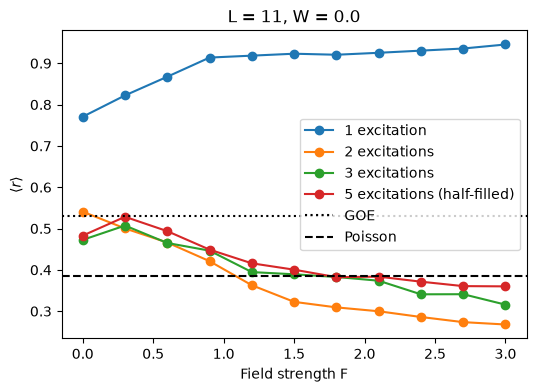

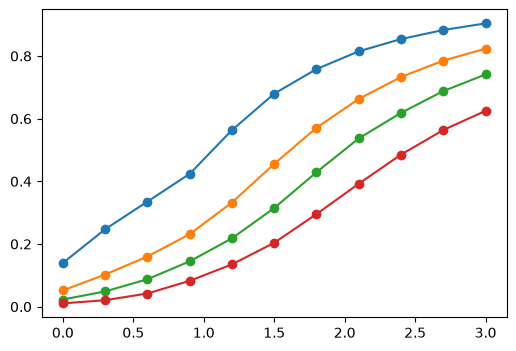

In [3]:
# ============================================================
# Imports
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations
from scipy.linalg import eigh


# ============================================================
# Basis: fixed number of excitations (up spins)
# ============================================================

def fixed_excitation_basis(L, n_up):
    """
    Generate all spin configurations with n_up up spins.

    n_up = L//2  -> half-filled sector
    n_up = 1     -> single-excitation sector

    State convention:
    1 = spin up
    0 = spin down
    """

    basis = []

    for ups in combinations(range(L), n_up):

        state = [0]*L

        for i in ups:
            state[i] = 1

        basis.append(tuple(state))

    return basis



def basis_index(basis):

    return {
        state:i for i,state in enumerate(basis)
    }



# ============================================================
# Heisenberg Hamiltonian (generalized to n_up excitations)
# ============================================================
def build_heisenberg(L, n_up=None, J0=1.0, Jz=1.0, F=0.0, h=None):
    """
    Anisotropic Heisenberg (XXZ) Hamiltonian with tilt:

    H = sum_j [ J0 (SxSx + SySy) + Jz SzSz ]_{j,j+1}
        + sum_j F*j*Sz_j
        + sum_j h_j*Sz_j

    Restricted to a fixed n_up (excitation number) sector.

    Parameters
    ----------
    L    : system size
    n_up : number of up spins (excitations).
           Default: L//2 (half-filled sector)
           Set n_up=1 for the single-excitation sector.
    J0   : XY (flip-flop) coupling
    Jz   : Ising (ZZ) coupling
    F    : linear tilt field strength
    h    : array of random on-site fields (optional)

    Returns
    -------
    H, basis
    """

    if n_up is None:
        n_up = L // 2

    basis = fixed_excitation_basis(L, n_up)
    index = basis_index(basis)

    dim = len(basis)

    H = np.zeros((dim,dim),dtype=float)


    for n,state in enumerate(basis):


        # -----------------------------
        # on-site Sz terms: tilt + random field
        # -----------------------------

        for i in range(L):

            sz = 0.5 if state[i]==1 else -0.5

            # linear tilt field F*j*Sz_j
            H[n,n] += F*i*sz

            # random field h_j*Sz_j
            if h is not None:
                H[n,n] += h[i]*sz



        # -----------------------------
        # nearest-neighbor XXZ terms
        # -----------------------------

        for i in range(L-1):

            si = 1 if state[i]==1 else -1
            sj = 1 if state[i+1]==1 else -1


            # Jz SzSz contribution

            H[n,n] += Jz*0.25*si*sj



            # J0 (SxSx + SySy)
            # flips neighboring opposite spins

            if state[i] != state[i+1]:


                new_state = list(state)

                new_state[i],new_state[i+1] = (
                    new_state[i+1],
                    new_state[i]
                )

                new_state = tuple(new_state)

                m = index[new_state]


                H[m,n] += J0*0.5


    return H,basis



# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H):

    evals,evecs = eigh(H)

    return evals,evecs



# ============================================================
# Select middle of spectrum
# ============================================================

def middle_spectrum(evals,evecs,frac=0.2):
    """
    Keep fraction of states around the middle energy.
    """

    N=len(evals)

    start=int(N*(0.5-frac/2))
    end  =int(N*(0.5+frac/2))


    return evals[start:end], evecs[:,start:end]



# ============================================================
# Level statistics
# ============================================================

def level_spacing_ratio(evals):

    evals=np.sort(evals)

    spacings=np.diff(evals)


    r=[]

    for i in range(len(spacings)-1):

        r.append(
            min(spacings[i],spacings[i+1]) /
            max(spacings[i],spacings[i+1])
        )


    return np.mean(r)



# ============================================================
# Inverse participation ratio
# ============================================================

def compute_IPR(evecs):
    """
    IPR = sum_i |psi_i|^4
    """

    ipr=[]


    for n in range(evecs.shape[1]):

        psi=evecs[:,n]

        ipr.append(
            np.sum(np.abs(psi)**4)
        )


    return np.array(ipr)



# ============================================================
# Single disorder realization
# ============================================================

def analyze_realization(L,W,n_up=None,J0=1.0,Jz=1.0,F=0.0,frac=0.2):
    """
    One disorder realization.

    h_i uniform[-W,W]

    n_up : excitation number sector (None -> half-filled)
    """

    h=np.random.uniform(-W,W,L)


    H,basis = build_heisenberg(
        L=L,
        n_up=n_up,
        J0=J0,
        Jz=Jz,
        F=F,
        h=h
    )


    evals,evecs = diagonalize(H)


    evals_mid,evecs_mid = middle_spectrum(
        evals,
        evecs,
        frac
    )


    # Single-excitation sector has dim = L, which can be too
    # small for a meaningful gap-ratio average once you also
    # restrict to the "middle" — guard against too-few levels.
    if len(evals_mid) < 3:
        r = np.nan
    else:
        r = level_spacing_ratio(evals_mid)

    ipr = np.mean(
        compute_IPR(evecs_mid)
    )


    return r,ipr

# ============================================================
# Disorder averaging
# ============================================================

def disorder_average(
        L,
        W,
        n_up=None,
        realizations=50,
        J0=1.0,
        Jz=1.0,
        F=0.0,
        frac=1):


    r_values=[]
    ipr_values=[]


    for _ in range(realizations):

        r,ipr = analyze_realization(
            L=L,
            W=W,
            n_up=n_up,
            J0=J0,
            Jz=Jz,
            F=F,
            frac=frac
        )

        r_values.append(r)
        ipr_values.append(ipr)


    return (
        np.nanmean(r_values),
        np.nanstd(r_values),
        np.mean(ipr_values),
        np.std(ipr_values)
    )


# ============================================================
# F sweep across multiple excitation-number sectors, fixed L
# ============================================================

L = 11
F_values = np.linspace(0, 3, 11)

# Sectors to compare: 1, 2, 3 excitations, and half-filling
n_up_values = [1, 2, 3, L // 2]

results = {}   # n_up -> dict with 'r' and 'ipr' lists

for n_up in n_up_values:

    r_results = []
    ipr_results = []

    for F in F_values:

        r_mean, r_std, ipr_mean, ipr_std = disorder_average(
            L=L, W=0.1, n_up=n_up,
            realizations=20,
            J0=1, Jz=1, F=F, frac=1
        )

        r_results.append(r_mean)
        ipr_results.append(ipr_mean)

    results[n_up] = {
        "r": r_results,
        "ipr": ipr_results
    }


# ------------------------------------------------------------
# Plot <r> for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(6,4))

for n_up in n_up_values:
    label = f"{n_up} excitation" if n_up == 1 else f"{n_up} excitations"
    if n_up == L // 2:
        label += " (half-filled)"
    plt.plot(F_values, results[n_up]["r"], marker="o", label=label)

plt.axhline(0.5307, linestyle=":", color="k", label="GOE")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson")
plt.xlabel("Field strength F")
plt.ylabel(r"$\langle r\rangle$")
plt.title(f"L = {L}, W = 0.0")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot IPR for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(6,4))

for n_up in n_up_values:
    label = f"{n_up} excitation" if n_up == 1 else f"{n_up} excitations"
    if n_up == L // 2:
        label += " (half-filled)"
    plt.plot(F_values, results[n_up]["ipr"], marker="o", label=label)


## Vary N

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.linalg import eigh
from collections import defaultdict


# ============================================================
# Basis: fixed n_up sector (generalizes half-filled)
# ============================================================

def fixed_excitation_basis(L, n_up):
    basis = []
    for ups in combinations(range(L), n_up):
        state = [0] * L
        for i in ups:
            state[i] = 1
        basis.append(tuple(state))
    return basis

def basis_index(basis):
    return {state: i for i, state in enumerate(basis)}


# ============================================================
# Heisenberg Hamiltonian (generalized to n_up excitations)
# ============================================================

def build_heisenberg(L, n_up=None, J0=1.0, Jz=1.0, F=0.0, h=None):
    """
    Anisotropic Heisenberg (XXZ) Hamiltonian with tilt:

    H = sum_j [ J0 (SxSx + SySy) + Jz SzSz ]_{j,j+1}
        + sum_j F*j*Sz_j
        + sum_j h_j*Sz_j

    Restricted to a fixed n_up (excitation number) sector.
    """
    if n_up is None:
        n_up = L // 2

    basis = fixed_excitation_basis(L, n_up)
    index = basis_index(basis)
    dim = len(basis)
    H = np.zeros((dim, dim), dtype=float)

    for n, state in enumerate(basis):

        # -----------------------------
        # On-site Sz terms: tilt + random field
        # -----------------------------
        for i in range(L):
            sz = 0.5 if state[i] == 1 else -0.5

            # Linear tilt field F*i*Sz_i
            H[n, n] += F * i * sz

            # Random field h_i*Sz_i
            if h is not None:
                H[n, n] += h[i] * sz

        # -----------------------------
        # Nearest-neighbor XXZ terms
        # -----------------------------
        for i in range(L - 1):
            si = 1 if state[i] == 1 else -1
            sj = 1 if state[i + 1] == 1 else -1

            # Jz SzSz contribution
            H[n, n] += Jz * 0.25 * si * sj

            # J0 (SxSx + SySy) -- flips neighboring opposite spins
            if state[i] != state[i + 1]:
                new_state = list(state)
                new_state[i], new_state[i + 1] = new_state[i + 1], new_state[i]
                new_state = tuple(new_state)

                m = index[new_state]
                H[m, n] += J0 * 0.5

    return H, basis


# ============================================================
# Diagonalization / Statistics Helpers
# ============================================================

def diagonalize(H):
    return eigh(H)

def middle_spectrum(evals, evecs, frac=1.0):
    N = len(evals)
    start = int(N * (0.5 - frac / 2))
    end = int(N * (0.5 + frac / 2))
    return evals[start:end], evecs[:, start:end]

def level_spacing_ratio(evals):
    evals = np.sort(evals)
    spacings = np.diff(evals)
    if len(spacings) < 2:
        return np.nan
    r = [min(spacings[i], spacings[i+1]) / max(spacings[i], spacings[i+1])
         for i in range(len(spacings) - 1)]
    return np.mean(r)

def compute_IPR(evecs):
    return np.array([np.sum(np.abs(evecs[:, n]) ** 4) for n in range(evecs.shape[1])])


# ============================================================
# Left-Half Entanglement Entropy
# ============================================================

def entanglement_entropy(psi, basis, cut):
    """
    psi   : state vector in the occupation basis (length = dim)
    basis : list of L-site tuples matching psi's ordering
    cut   : number of sites in the "left half" (0..cut-1)
    """
    amp_map = defaultdict(dict)

    for coeff, state in zip(psi, basis):
        left = state[:cut]
        right = state[cut:]
        amp_map[left][right] = coeff

    lefts = list(amp_map.keys())
    rights = sorted(set(r for d in amp_map.values() for r in d))
    right_index = {r: j for j, r in enumerate(rights)}

    M = np.zeros((len(lefts), len(rights)))
    for i, l in enumerate(lefts):
        for r, val in amp_map[l].items():
            M[i, right_index[r]] = val

    svals = np.linalg.svd(M, compute_uv=False)
    p = svals ** 2
    p = p[p > 1e-14]
    p = p / p.sum()  # Guard against normalization drift

    return -np.sum(p * np.log(p))


# ============================================================
# Direct Realization Analysis (No Symmetry Blocks)
# ============================================================

def analyze_realization(L, n_up, W, J0=1.0, Jz=1.0, F=0.0, frac=1.0, cut=None):

    if cut is None:
        cut = L // 2

    # Standard uncorrelated disorder since inversion symmetry is absent (F != 0)
    h = np.random.uniform(-W, W, L) if W > 0 else None

    # Construct and diagonalize full Hamiltonian directly
    H, basis = build_heisenberg(L, n_up=n_up, J0=J0, Jz=Jz, F=F, h=h)
    evals, evecs = diagonalize(H)

    # Focus on the target fraction around middle-spectrum (e.g. infinite temperature limit)
    evals_mid, evecs_mid = middle_spectrum(evals, evecs, frac=frac)

    # Spectral & Spatial Diagnostics
    r = level_spacing_ratio(evals_mid)
    ipr = np.mean(compute_IPR(evecs_mid))
    
    # Entanglement entropy calculated directly on the eigenvectors
    S_vals = [
        entanglement_entropy(evecs_mid[:, k], basis, cut) 
        for k in range(evecs_mid.shape[1])
    ]

    return r, ipr, np.mean(S_vals)


def disorder_average(L, n_up, W, realizations=50, J0=1.0, Jz=1.0, F=0.0, frac=1.0, cut=None):

    r_values, ipr_values, S_values = [], [], []

    for _ in range(realizations):
        r, ipr, S = analyze_realization(
            L=L, n_up=n_up, W=W, J0=J0, Jz=Jz, F=F, frac=frac, cut=cut
        )
        r_values.append(r)
        ipr_values.append(ipr)
        S_values.append(S)

    return (
        np.nanmean(r_values), np.nanstd(r_values),
        np.mean(ipr_values), np.std(ipr_values),
        np.mean(S_values), np.std(S_values)
    )

#### W=0

In [ ]:
import csv
import math
import os
import numpy as np

# ============================================================
# Parameter sweep over tilt field strength F
# Tilted Heisenberg Chain (Stark MBL transition)
# Fixed parameters: Jz, J0, W
# ============================================================

# System sizes L to sweep over
L_list = [10, 11, 12, 14]

# Model Parameters
Jz = 1.0         # Fixed Ising coupling
J0 = 1.0         # Fixed XY coupling
W = 0.0          # Fixed disorder strength (Clean Stark MBL)
F_values = np.linspace(0.0, 4.0, 11)  # Sweeping linear field strength F

# Set realizations to 1 if clean system (W=0), otherwise keep >1
num_realizations = 1 if W == 0.0 else 10

output_dir = "MBL_Heisenberg_Tilted"
os.makedirs(output_dir, exist_ok=True)

fieldnames = [
    "n_up", "Jz", "J0", "F", "W", "L",
    "r_mean", "r_std",
    "ipr_mean", "ipr_std",
    "S_mean", "S_std"
]

for L in L_list:
    n_up_values = sorted(list(set([1, 2, 3, L // 2])))
    
    # Updated output file name to reflect fixed parameters
    output_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    
    print(f"\n--- Starting F sweep for L = {L} (Jz = {Jz}, J0 = {J0}, W = {W}) ---")

    with open(output_file, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for n_up in n_up_values:
            for F in F_values:

                r_mean, r_std, ipr_mean, ipr_std, S_mean, S_std = disorder_average(
                    L=L, n_up=n_up, W=W, realizations=num_realizations, J0=J0, Jz=Jz, F=F, frac=1.0
                )

                row = {
                    "n_up": n_up, "Jz": Jz, "J0": J0, "F": F, "W": W, "L": L,
                    "r_mean": r_mean, "r_std": r_std,
                    "ipr_mean": ipr_mean, "ipr_std": ipr_std,
                    "S_mean": S_mean, "S_std": S_std,
                }

                writer.writerow(row)
                f.flush()

                # Print statement now tracks F properly
                print(
                    f"[L={L:2d}] n_up={n_up:2d}  F={F:5.2f}  "
                    f"<r>={r_mean:.4f}  IPR={ipr_mean:.4f}  S_ent={S_mean:.4f}"
                )

    # Save Page estimates for maximal Hilbert space dimension of sub-blocks
    cut = L // 2
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    with open(page_file, "w", newline="") as f:
        writer_page = csv.DictWriter(f, fieldnames=["n_up", "S_max_estimate"])
        writer_page.writeheader()

        for n_up in n_up_values:
            left_dim = sum(math.comb(cut, k) for k in range(min(n_up, cut) + 1))
            right_dim = sum(math.comb(L - cut, k) for k in range(min(n_up, L - cut) + 1))
            
            S_max = np.log(min(left_dim, right_dim))
            writer_page.writerow({"n_up": n_up, "S_max_estimate": S_max})

print(f"\nSweep complete. All results written to '{output_dir}/'")

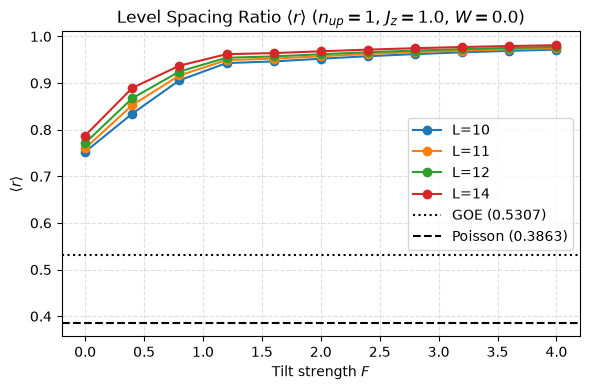

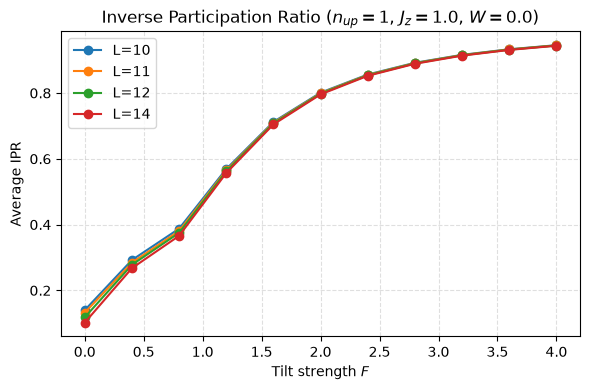

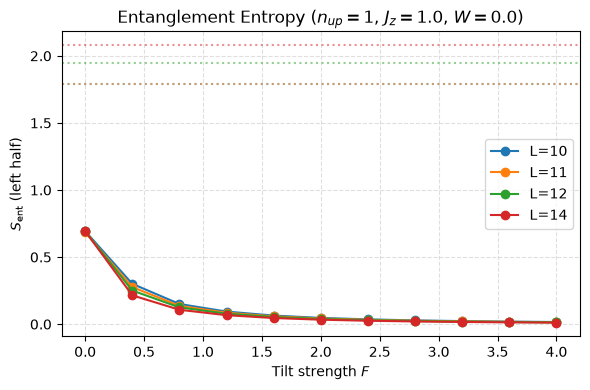

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL_Heisenberg_Tilted"
L_values = [10, 11, 12, 14]
Jz = 1.0
W = 0.0
n_up = 1

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter by n_up and sort by the swept variable F
        data_dict[L] = df[df["n_up"] == n_up].sort_values("F")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"Level Spacing Ratio $\langle r\rangle$ ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"Tilt strength $F$")
plt.ylabel("Average IPR")
plt.title(rf"Inverse Participation Ratio ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["F"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

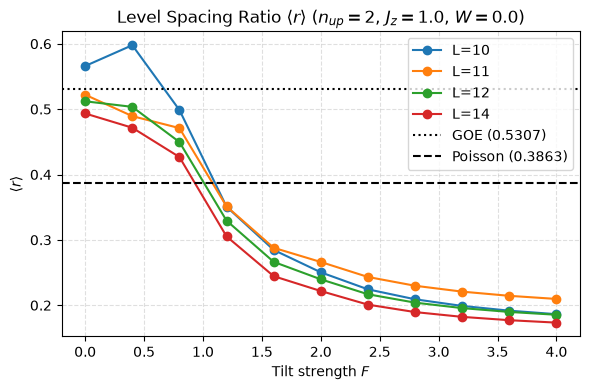

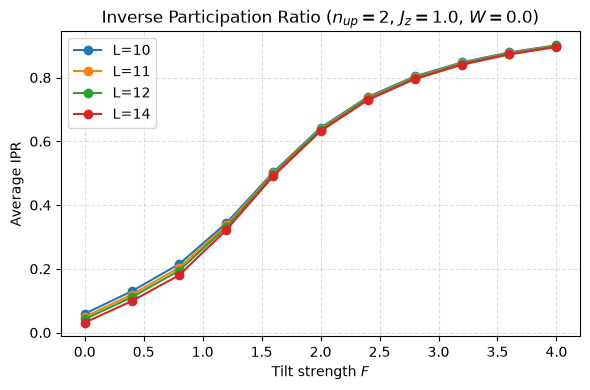

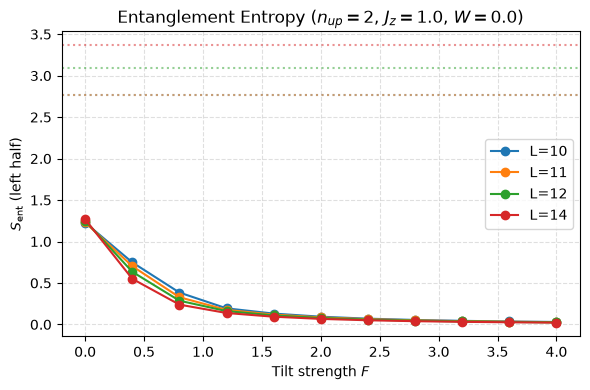

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL_Heisenberg_Tilted"
L_values = [10, 11, 12, 14]
Jz = 1.0
W = 0.0
n_up = 2

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter by n_up and sort by the swept variable F
        data_dict[L] = df[df["n_up"] == n_up].sort_values("F")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"Level Spacing Ratio $\langle r\rangle$ ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"Tilt strength $F$")
plt.ylabel("Average IPR")
plt.title(rf"Inverse Participation Ratio ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["F"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

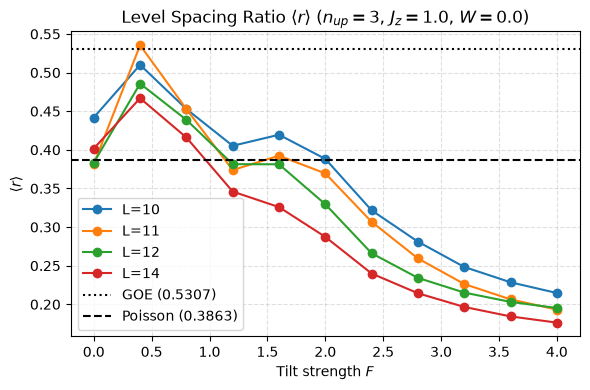

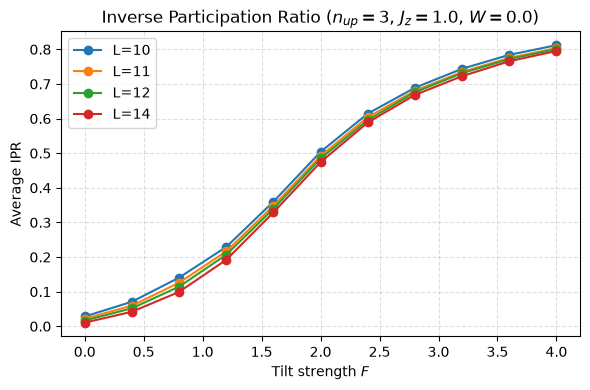

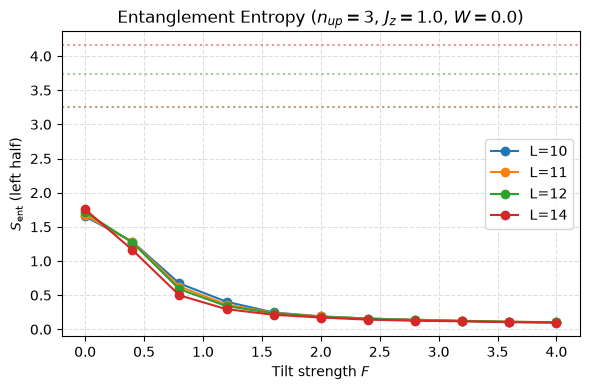

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL_Heisenberg_Tilted"
L_values = [10, 11, 12, 14]
Jz = 1.0
W = 0.0
n_up = 3

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter by n_up and sort by the swept variable F
        data_dict[L] = df[df["n_up"] == n_up].sort_values("F")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"Level Spacing Ratio $\langle r\rangle$ ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"Tilt strength $F$")
plt.ylabel("Average IPR")
plt.title(rf"Inverse Participation Ratio ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["F"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

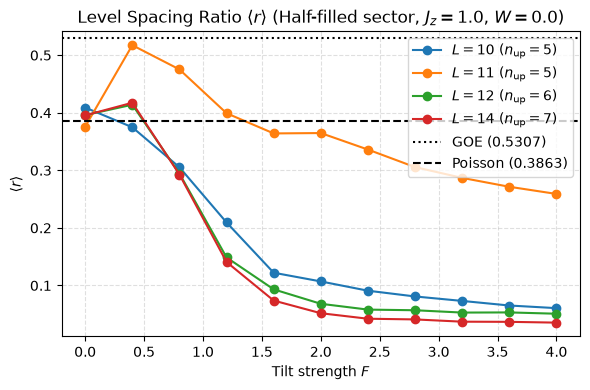

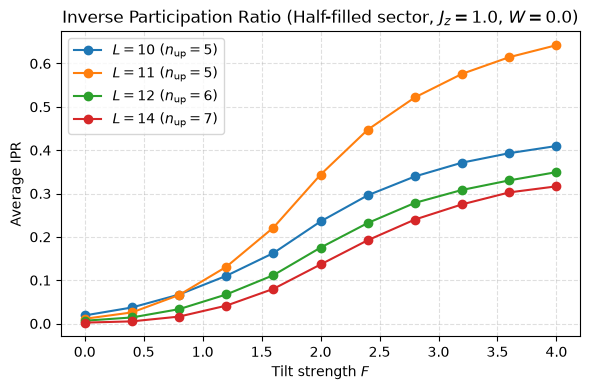

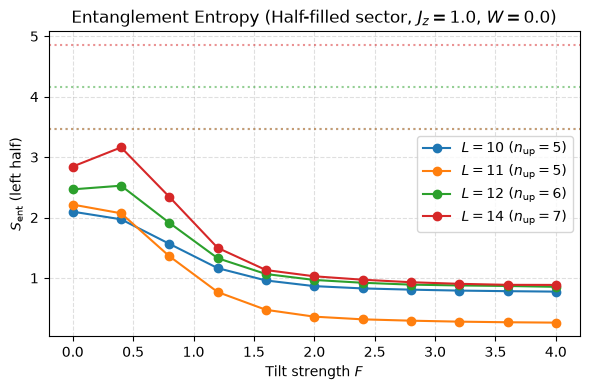

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL_Heisenberg_Tilted"
L_values = [10, 11, 12, 14]
Jz = 1.0
W = 0.0

# Pre-load data into dictionaries for half-filling sectors
data_dict = {}
page_dict = {}

for L in L_values:
    n_up = L // 2  # Dynamic half-filling sector for each L

    sweep_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter for half-filling n_up = L // 2 and sort by F
        data_dict[L] = df[df["n_up"] == n_up].sort_values("F")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs F for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["F"],
        sub["r_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"Level Spacing Ratio $\langle r\rangle$ (Half-filled sector, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs F for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["F"],
        sub["ipr_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel("Average IPR")
plt.title(rf"Inverse Participation Ratio (Half-filled sector, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs F for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    (line,) = plt.plot(
        sub["F"],
        sub["S_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

    # Plot Page estimate reference line corresponding to this L's half-filled sector
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy (Half-filled sector, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
###

#### W=0.2

In [42]:
import csv
import math
import os
import numpy as np

# ============================================================
# Parameter sweep over tilt field strength F
# Tilted Heisenberg Chain (Stark MBL transition)
# Fixed parameters: Jz, J0, W
# ============================================================

# System sizes L to sweep over
L_list = [10, 11, 12]

# Model Parameters
Jz = 1.0         # Fixed Ising coupling
J0 = 1.0         # Fixed XY coupling
W = 0.2          # Fixed disorder strength (Clean Stark MBL)
F_values = np.linspace(0.0, 4.0, 11)  # Sweeping linear field strength F

# Set realizations to 1 if clean system (W=0), otherwise keep >1
num_realizations = 1 if W == 0.0 else 120

output_dir = "MBL_Heisenberg_Tilted"
os.makedirs(output_dir, exist_ok=True)

fieldnames = [
    "n_up", "Jz", "J0", "F", "W", "L",
    "r_mean", "r_std",
    "ipr_mean", "ipr_std",
    "S_mean", "S_std"
]

for L in L_list:
    n_up_values = sorted(list(set([1, 2, 3, L // 2])))
    
    # Updated output file name to reflect fixed parameters
    output_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    
    print(f"\n--- Starting F sweep for L = {L} (Jz = {Jz}, J0 = {J0}, W = {W}) ---")

    with open(output_file, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for n_up in n_up_values:
            for F in F_values:

                r_mean, r_std, ipr_mean, ipr_std, S_mean, S_std = disorder_average(
                    L=L, n_up=n_up, W=W, realizations=num_realizations, J0=J0, Jz=Jz, F=F, frac=1.0
                )

                row = {
                    "n_up": n_up, "Jz": Jz, "J0": J0, "F": F, "W": W, "L": L,
                    "r_mean": r_mean, "r_std": r_std,
                    "ipr_mean": ipr_mean, "ipr_std": ipr_std,
                    "S_mean": S_mean, "S_std": S_std,
                }

                writer.writerow(row)
                f.flush()

                # Print statement now tracks F properly
                print(
                    f"[L={L:2d}] n_up={n_up:2d}  F={F:5.2f}  "
                    f"<r>={r_mean:.4f}  IPR={ipr_mean:.4f}  S_ent={S_mean:.4f}"
                )

    # Save Page estimates for maximal Hilbert space dimension of sub-blocks
    cut = L // 2
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    with open(page_file, "w", newline="") as f:
        writer_page = csv.DictWriter(f, fieldnames=["n_up", "S_max_estimate"])
        writer_page.writeheader()

        for n_up in n_up_values:
            left_dim = sum(math.comb(cut, k) for k in range(min(n_up, cut) + 1))
            right_dim = sum(math.comb(L - cut, k) for k in range(min(n_up, L - cut) + 1))
            
            S_max = np.log(min(left_dim, right_dim))
            writer_page.writerow({"n_up": n_up, "S_max_estimate": S_max})

print(f"\nSweep complete. All results written to '{output_dir}/'")


--- Starting F sweep for L = 10 (Jz = 1.0, J0 = 1.0, W = 0.2) ---
[L=10] n_up= 1  F= 0.00  <r>=0.7537  IPR=0.1634  S_ent=0.6195
[L=10] n_up= 1  F= 0.40  <r>=0.7958  IPR=0.2941  S_ent=0.2979
[L=10] n_up= 1  F= 0.80  <r>=0.8843  IPR=0.3934  S_ent=0.1476
[L=10] n_up= 1  F= 1.20  <r>=0.8813  IPR=0.5637  S_ent=0.0961
[L=10] n_up= 1  F= 1.60  <r>=0.8803  IPR=0.7091  S_ent=0.0664
[L=10] n_up= 1  F= 2.00  <r>=0.8873  IPR=0.7983  S_ent=0.0472
[L=10] n_up= 1  F= 2.40  <r>=0.9007  IPR=0.8546  S_ent=0.0357
[L=10] n_up= 1  F= 2.80  <r>=0.9110  IPR=0.8911  S_ent=0.0284
[L=10] n_up= 1  F= 3.20  <r>=0.9185  IPR=0.9154  S_ent=0.0227
[L=10] n_up= 1  F= 3.60  <r>=0.9289  IPR=0.9327  S_ent=0.0191
[L=10] n_up= 1  F= 4.00  <r>=0.9329  IPR=0.9451  S_ent=0.0162
[L=10] n_up= 2  F= 0.00  <r>=0.5175  IPR=0.0659  S_ent=1.2203
[L=10] n_up= 2  F= 0.40  <r>=0.5163  IPR=0.1319  S_ent=0.7530
[L=10] n_up= 2  F= 0.80  <r>=0.4459  IPR=0.2202  S_ent=0.3599
[L=10] n_up= 2  F= 1.20  <r>=0.3811  IPR=0.3392  S_ent=0.2010
[L=

KeyboardInterrupt: 

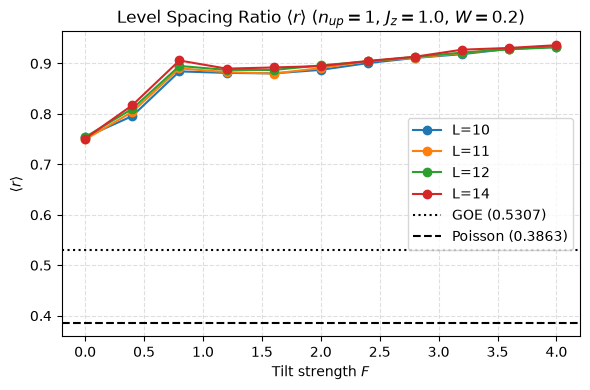

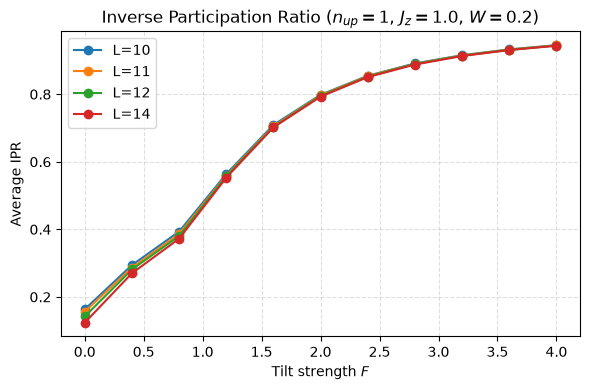

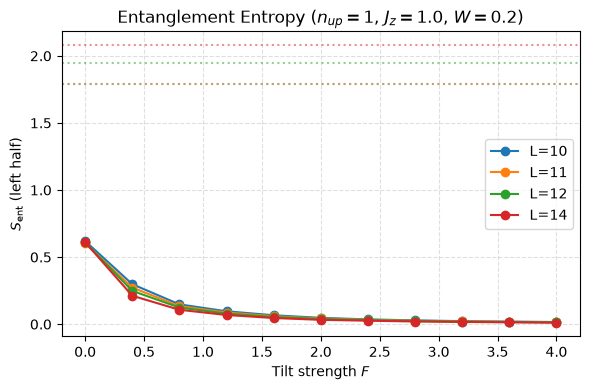

In [43]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL_Heisenberg_Tilted"
L_values = [10, 11, 12, 14]
Jz = 1.0
W = 0.2
n_up = 1

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter by n_up and sort by the swept variable F
        data_dict[L] = df[df["n_up"] == n_up].sort_values("F")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"Level Spacing Ratio $\langle r\rangle$ ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"Tilt strength $F$")
plt.ylabel("Average IPR")
plt.title(rf"Inverse Participation Ratio ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["F"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

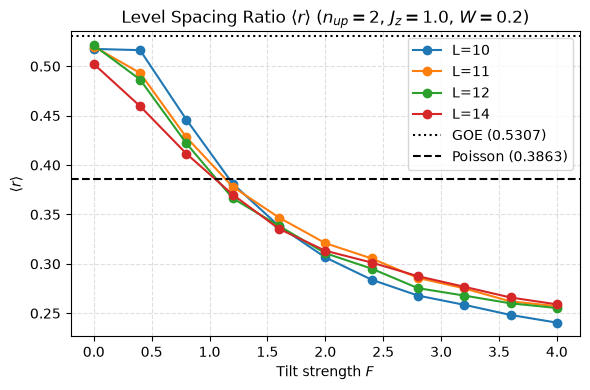

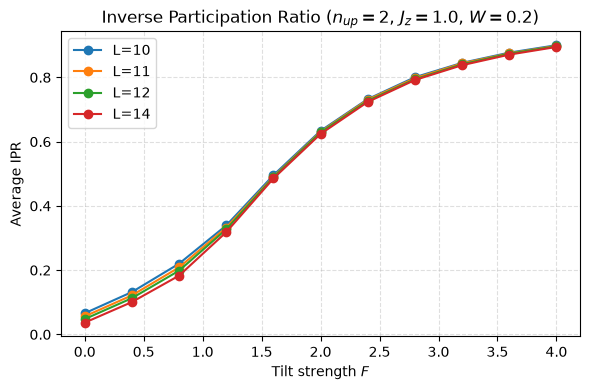

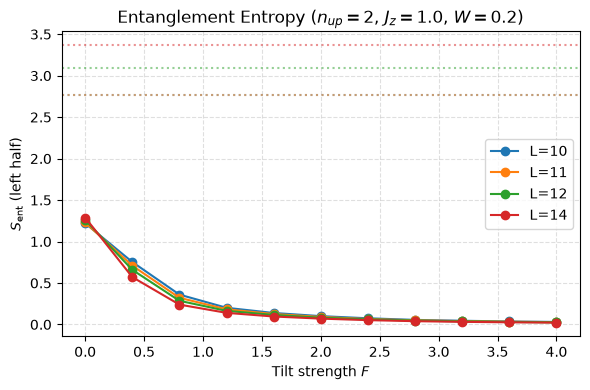

In [44]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL_Heisenberg_Tilted"
L_values = [10, 11, 12, 14]
Jz = 1.0
W = 0.2
n_up = 2

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter by n_up and sort by the swept variable F
        data_dict[L] = df[df["n_up"] == n_up].sort_values("F")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"Level Spacing Ratio $\langle r\rangle$ ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"Tilt strength $F$")
plt.ylabel("Average IPR")
plt.title(rf"Inverse Participation Ratio ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["F"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

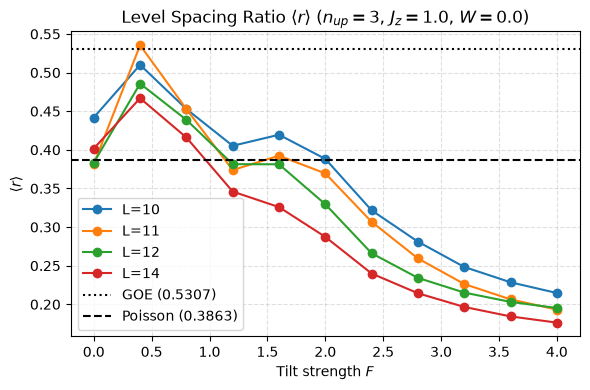

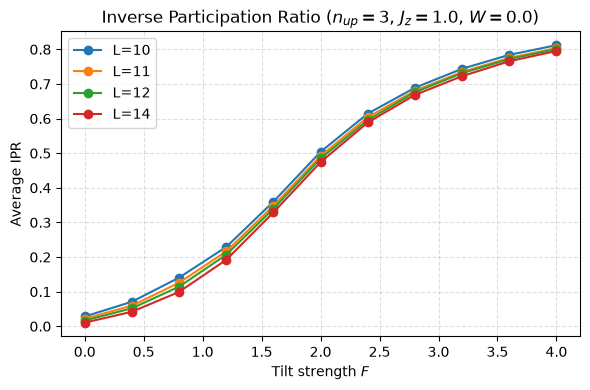

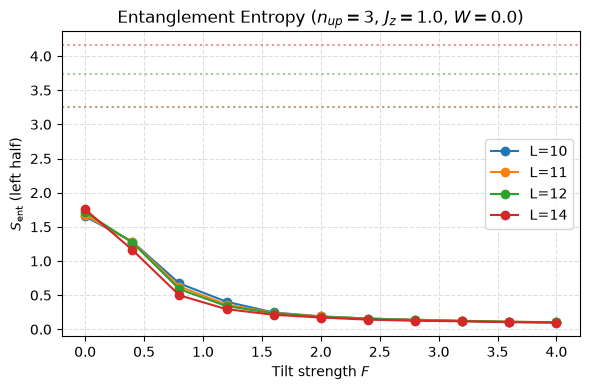

In [45]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL_Heisenberg_Tilted"
L_values = [10, 11, 12, 14]
Jz = 1.0
W = 0.0
n_up = 3

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter by n_up and sort by the swept variable F
        data_dict[L] = df[df["n_up"] == n_up].sort_values("F")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"Level Spacing Ratio $\langle r\rangle$ ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["F"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"Tilt strength $F$")
plt.ylabel("Average IPR")
plt.title(rf"Inverse Participation Ratio ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs F for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["F"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy ($n_{{up}}={n_up}$, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

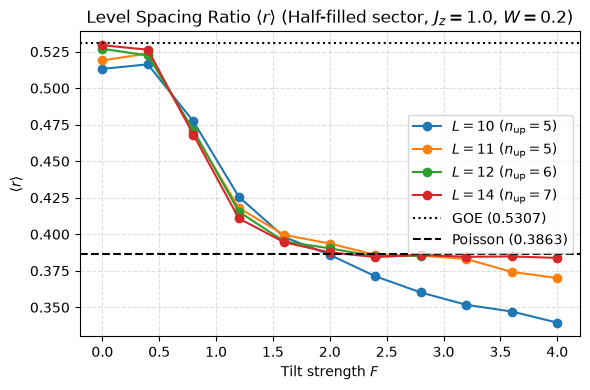

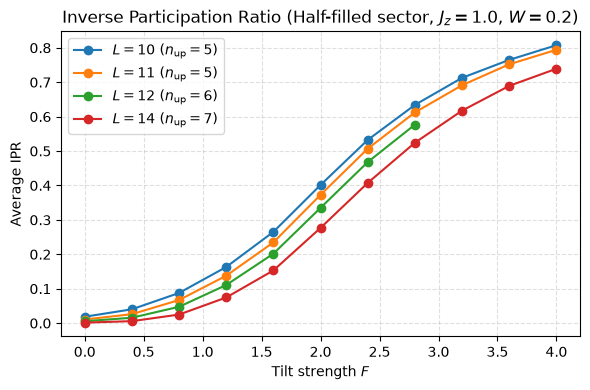

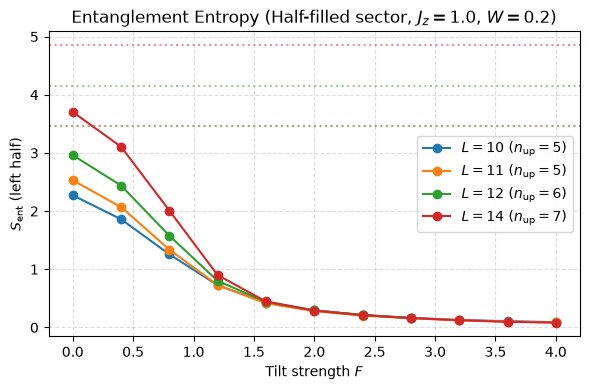

In [46]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL_Heisenberg_Tilted"
L_values = [10, 11, 12, 14]
Jz = 1.0
W = 0.2

# Pre-load data into dictionaries for half-filling sectors
data_dict = {}
page_dict = {}

for L in L_values:
    n_up = L // 2  # Dynamic half-filling sector for each L

    sweep_file = os.path.join(output_dir, f"sweep_L{L}_Jz{Jz}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter for half-filling n_up = L // 2 and sort by F
        data_dict[L] = df[df["n_up"] == n_up].sort_values("F")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs F for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["F"],
        sub["r_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"Level Spacing Ratio $\langle r\rangle$ (Half-filled sector, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs F for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["F"],
        sub["ipr_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel("Average IPR")
plt.title(rf"Inverse Participation Ratio (Half-filled sector, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs F for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    (line,) = plt.plot(
        sub["F"],
        sub["S_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

    # Plot Page estimate reference line corresponding to this L's half-filled sector
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"Tilt strength $F$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy (Half-filled sector, $J_z={Jz}$, $W={W}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
###

# Our Hamiltonian

Redoing the same thing in our hamiltonian

The major structural shift here is moving from a short-range anisotropic model to a **power-law long-range Ising model with nearest-neighbor spin flips**, while explicitly maintaining **reflection symmetry ($P$)** to eliminate spectral hybridizations (level repulsion artifacts from discrete symmetries).

---

### Codeblock Breakdown

#### 1. Hilbert Space Construction

```python
def fixed_excitation_basis(L, n_up): ...
def basis_index(basis): ...

```

* **What:** Constructs the standard $S^z_{\text{total}}$ conservation sector with $n_{\uparrow}$ up-spins (dimension $\binom{L}{n_{\uparrow}}$) and maps each state tuple to a integer index.
* **Why:** The total magnetization $\hat{S}^z = \sum_i \sigma_i^z$ is still a good quantum number for this Hamiltonian, allowing you to project out irrelevant magnetization sectors and focus on specific particle/excitation sectors.

---

#### 2. Long-Range Projected Hamiltonian

```python
def build_H_longrange_projected(L, n_up, Jz, alpha, Jx, h=None): ...

```

* **What:** Assembles the matrix elements for the long-range interacting system:

$$\hat{H} = \sum_{i<j} \frac{J_z}{\vert{}i-j\vert{}^\alpha} \sigma_i^z \sigma_j^z + J_x \sum_{i=0}^{L-2} (\sigma_i^+ \sigma_{i+1}^- + \sigma_i^- \sigma_{i+1}^+) + \sum_{i=0}^{L-1} h_i \sigma_i^z$$


* **Why:**
* **Diagonal ($H_{n,n}$):** Evaluates all pair interactions decaying as $1/r^\alpha$. When $\alpha \to \infty$, it reduces to nearest-neighbor Ising interactions; when $\alpha \to 0$, it becomes a fully connected infinite-range model. On-site field terms $h_i \sigma_i^z$ are also added to the diagonal.
* **Off-Diagonal ($H_{m,n}$):** The $J_x$ flip-flop term allows excitations to hop between adjacent sites ($\vert{}\dots \uparrow \downarrow \dots \rangle \leftrightarrow \vert{}\dots \downarrow \uparrow \dots \rangle$).



---



#### 3. Reflection Symmetry & Parity Block-Diagonalization

```python
def reflection_blocks(basis): ...
def block_diagonalize_by_parity(H, basis): ...

```

##### **Overview & Purpose**

This section constructs an orthogonal, unitary change-of-basis transformation $U$ that projects the Hamiltonian matrix $H$ (already restricted to a fixed $n_\uparrow$ excitation sector) into explicit spatial reflection parity sub-blocks ($P = \pm 1$).

$$\hat{H}_{\text{rot}} = U^\dagger \hat{H} U = \begin{pmatrix} \mathbf{H_{\text{even}}} & \mathbf{0} \\ \mathbf{0} & \mathbf{H_{\text{odd}}} \end{pmatrix}$$

##### **Mathematical Formulation**

Spatial reflection acts as a discrete symmetry operator $\hat{P}$ reversing site indices $i \to L - 1 - i$. Because $\hat{P}^2 = \mathbb{I}$, its eigenvalues are strictly bounded to $P = \pm 1$.

1. **Self-Mirrored (Palindromic) States ($\vert{}n\rangle = \vert{}\tilde{n}\rangle$):**
* States such as $\vert{}01110\rangle$ or $\vert{}10101\rangle$ are invariant under spatial reversal.
* They are automatically pure even parity eigenstates: $\hat{P}\vert{}n\rangle = +1\vert{}n\rangle$.
* They contribute exclusively to the $P = +1$ subspace.


2. **Asymmetric Mirror Pairs ($\vert{}n\rangle \neq \vert{}\tilde{n}\rangle$):**
* Asymmetric computational basis states (e.g., $\vert{}11100\rangle$ and $\vert{}00111\rangle$) are not eigenstates of $\hat{P}$.
* We construct orthonormal parity eigenstates via symmetric and antisymmetric linear superpositions:

$$\vert{}v_{\text{even}}\rangle = \frac{1}{\sqrt{2}}(\vert{}n\rangle + \vert{}\tilde{n}\rangle) \quad \implies \quad \hat{P}\vert{}v_{\text{even}}\rangle = +1\vert{}v_{\text{even}}\rangle$$


$$\vert{}v_{\text{odd}}\rangle = \frac{1}{\sqrt{2}}(\vert{}n\rangle - \vert{}\tilde{n}\rangle) \quad \implies \quad \hat{P}\vert{}v_{\text{odd}}\rangle = -1\vert{}v_{\text{odd}}\rangle$$





##### **Why This Projection Is Essential**

* **Eliminating False Integrability Artifacts:** If $[\hat{H}, \hat{P}] = 0$, energy levels belonging to the even and odd parity sectors do not interact ($\langle v_{\text{even}} \vert{} \hat{H} \vert{} v_{\text{odd}} \rangle = 0$). Diagonalizing the full matrix without block-diagonalization causes the two independent spectra to superimpose. The resulting uncorrelated level crossings artificially drive the level spacing ratio down to Poisson statistics ($\langle r \rangle \to 0.3863$), giving the false impression of localization or integrability even when the internal physics of each sector is strongly chaotic GOE ($\langle r \rangle \approx 0.5307$).
* **Computational Acceleration:** Diagonalizing $H_{\text{even}}$ and $H_{\text{odd}}$ separately reduces numerical complexity from $\mathcal{O}(D^3)$ to $\mathcal{O}(D_{\text{even}}^3 + D_{\text{odd}}^3)$, achieving an $\approx 70\text{--}75\%$ speedup in total CPU runtime for dense diagonalization routines.

---

#### Step-by-Step Code Execution & Mechanics

##### 1. Basis Pair Matching (`reflection_blocks`)

The function iterates through the computational basis array, maintaining a boolean mask `visited` to ensure each basis pair is processed exactly once:

* **Mirror Lookup:** Reverses the binary tuple (`state[::-1]`) and retrieves its index $m$ via the hash map `basis_index`.
* **Branching Logic:**
* **If $m == n$ (Palindromic):** Appends a single unit vector $v[n] = 1.0$ to `even_vecs`.
* **If $m \neq n$ (Pair):** Builds $v_{\text{even}}$ with weights $+1/\sqrt{2}$ at positions $n$ and $m$, and $v_{\text{odd}}$ with weights $+1/\sqrt{2}$ at $n$ and $-1/\sqrt{2}$ at $m$. Marks both $n$ and $m$ as `True` in `visited`.


* **Matrix Assembly:** Stacks all even vectors followed by all odd vectors into columns:

$$U = \Big[ \mathbf{v}_{\text{even}, 1} \quad \dots \quad \mathbf{v}_{\text{even}, n_{\text{even}}} \quad \Big\vert{} \quad \mathbf{v}_{\text{odd}, 1} \quad \dots \quad \mathbf{v}_{\text{odd}, n_{\text{odd}}} \Big]$$



##### 2. Similarity Transformation & Block Slicing (`block_diagonalize_by_parity`)

* **Unitary Rotation:** Executes $H_{\text{rot}} = U^T H U$. Off-diagonal elements $\langle v_{\text{even}} \vert{} \hat{H} \vert{} v_{\text{odd}} \rangle$ evaluate to zero up to machine precision.
* **Block Extraction:**
```python
H_even = H_rot[:n_even, :n_even]  # Dimension: n_even x n_even
H_odd  = H_rot[n_even:, n_even:]  # Dimension: n_odd  x n_odd

```


* **Symmetry Integrity Check (`off_block_norm`):**
Calculates $\max(\vert{}H_{\text{rot}}[:n_{\text{even}}, n_{\text{even}}:]\vert{})$.
* If $[\hat{H}, \hat{P}] = 0$, `off_block_norm` $\lesssim 10^{-14}$.
* If `off_block_norm` $> 10^{-12}$, reflection symmetry is broken (e.g., due to non-symmetrized random disorder fields $h_i \neq h_{L-1-i}$ or linear field potential gradients $F \cdot i$).



---

#### 4. Entanglement Entropy & State Reconstruction

```python
def entanglement_entropy(psi, basis, cut): ...
def reconstruct_full_eigvecs(U_block, evecs_block, n_even, block="even"): ...

```

* **What:**
1. `reconstruct_full_eigvecs`: Transforms eigenvectors calculated within the parity subspace ($H_{\text{even}}$ or $H_{\text{odd}}$) back into the full site-occupation computational basis ($\vert{}\psi\rangle = U_{\text{sub}} \vert{}\psi_{\text{block}}\rangle$).
2. `entanglement_entropy`: Re-indexes the state vector into a bipartite coefficient matrix $M_{\text{left}, \text{right}}$, executes a Singular Value Decomposition (SVD) to obtain Schmidt coefficients $\lambda_k$, and computes the von Neumann half-chain entanglement entropy:

$$S_{\text{vN}} = -\sum_k p_k \ln p_k, \quad \text{where } p_k = \lambda_k^2$$




* **Why:** Spectral statistics ($\langle r \rangle$) and IPR depend on the choice of basis. Bipartite Entanglement Entropy provides an unambiguous, coordinate-free thermodynamic diagnostic:
* **Ergodic / Thermal States:** Display volume-law entanglement ($S_{\text{vN}} \propto \text{cut}$).
* **Localized / Integrable States:** Display area-law or logarithmic entanglement ($S_{\text{vN}} \sim \mathcal{O}(1)$).



---

#### 5. Symmetrized Disorder & Realization Execution

```python
def analyze_realization(...): ...
def disorder_average(...): ...

```

* **What:** Generates random disorder profiles constrained by spatial reflection symmetry ($h_i = h_{L-1-i}$), diagonalizes each parity sector independently, calculates diagnostics ($\langle r \rangle$, IPR, $S_{\text{vN}}$), and tracks `off_norm` (the maximum magnitude of off-block matrix elements in $U^\dagger H U$).
* **Why:**
* **Enforcing $[\hat{H}, \hat{P}] = 0$:** Standard random disorder $h_i \in [-W, W]$ breaks reflection symmetry, which would mix parity sectors. Symmetrizing $h_i = h_{L-1-i}$ preserves spatial parity under disorder, ensuring $H_{\text{even}}$ and $H_{\text{odd}}$ remain decoupled.
* **Sanity Check (`off_norm`):** Checking `np.max(np.abs(H_rot[:n_even, n_even:]))` confirms numeric precision—if `off_norm` $> 10^{-12}$, symmetry breaking has occurred.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.linalg import eigh


# ============================================================
# Basis: fixed n_up sector (generalizes half-filled)
# ============================================================

def fixed_excitation_basis(L, n_up):
    basis = []
    for ups in combinations(range(L), n_up):
        state = [0] * L
        for i in ups:
            state[i] = 1
        basis.append(tuple(state))
    return basis

def basis_index(basis):
    return {state: i for i, state in enumerate(basis)}


# ============================================================
# H0 + V in the fixed-n_up sector
#
# H0 = sum_{i<j} Jz/|i-j|^alpha * sigma_i^z sigma_j^z   (reflection symmetric)
# V  ~ Jx * flip-flop (nearest-neighbor)                (reflection symmetric)
# disorder: sum_i h_i sigma_i^z  -- SYMMETRIZED so [H,P]=0 holds exactly
# ============================================================

def build_H_longrange_projected(L, n_up, Jz, alpha, Jx, h=None):

    basis = fixed_excitation_basis(L, n_up)
    index = basis_index(basis)
    dim = len(basis)
    H = np.zeros((dim, dim), dtype=float)

    for n, state in enumerate(basis):

        diag = 0.0
        for i in range(L):
            si = 1 if state[i] == 1 else -1
            if h is not None:
                diag += h[i] * si
            for j in range(i + 1, L):
                sj = 1 if state[j] == 1 else -1
                diag += Jz / (abs(i - j) ** alpha) * si * sj
        H[n, n] = diag

        for i in range(L - 1):
            if state[i] != state[i + 1]:
                new_state = list(state)
                new_state[i], new_state[i + 1] = new_state[i + 1], new_state[i]
                new_state = tuple(new_state)
                m = index[new_state]
                H[m, n] += Jx

    return H, basis


# ============================================================
# Reflection symmetry: build the even/odd change-of-basis
# ============================================================

def reflection_blocks(basis):
    """
    Partition `basis` into P=+1 (even) and P=-1 (odd) combinations.

    Returns
    -------
    U        : (dim x dim) orthogonal change-of-basis matrix,
               columns = [even combos, odd combos]
    n_even   : number of even basis vectors (first n_even columns of U)
    """

    L = len(basis[0])
    index = basis_index(basis)
    dim = len(basis)

    visited = np.zeros(dim, dtype=bool)

    even_vecs = []
    odd_vecs = []

    for n, state in enumerate(basis):

        if visited[n]:
            continue

        mirrored = state[::-1]
        m = index[mirrored]

        if m == n:
            # self-mirrored (palindromic) state -> even only
            v = np.zeros(dim)
            v[n] = 1.0
            even_vecs.append(v)
            visited[n] = True
        else:
            v_even = np.zeros(dim)
            v_even[n] = 1/np.sqrt(2)
            v_even[m] = 1/np.sqrt(2)
            even_vecs.append(v_even)

            v_odd = np.zeros(dim)
            v_odd[n] = 1/np.sqrt(2)
            v_odd[m] = -1/np.sqrt(2)
            odd_vecs.append(v_odd)

            visited[n] = True
            visited[m] = True

    n_even = len(even_vecs)
    U = np.array(even_vecs + odd_vecs).T   # columns are basis vectors

    return U, n_even


def block_diagonalize_by_parity(H, basis):

    U, n_even = reflection_blocks(basis)

    H_rot = U.T @ H @ U   # exactly block-diagonal if [H,P]=0

    H_even = H_rot[:n_even, :n_even]
    H_odd  = H_rot[n_even:, n_even:]

    # sanity check: off-diagonal blocks should be ~0
    off_block_norm = np.max(np.abs(H_rot[:n_even, n_even:]))

    return H_even, H_odd, U, n_even, off_block_norm


# ============================================================
# Diagonalization / statistics helpers
# ============================================================

def diagonalize(H):
    return eigh(H)

def middle_spectrum(evals, evecs, frac=1.0):
    N = len(evals)
    start = int(N * (0.5 - frac / 2))
    end = int(N * (0.5 + frac / 2))
    return evals[start:end], evecs[:, start:end]

def level_spacing_ratio(evals):
    evals = np.sort(evals)
    spacings = np.diff(evals)
    if len(spacings) < 2:
        return np.nan
    r = [min(spacings[i], spacings[i+1]) / max(spacings[i], spacings[i+1])
         for i in range(len(spacings) - 1)]
    return np.mean(r)

def compute_IPR(evecs):
    return np.array([np.sum(np.abs(evecs[:, n]) ** 4) for n in range(evecs.shape[1])])


# ============================================================
# Left-half entanglement entropy (real ergodicity/localization probe)
# ============================================================

def entanglement_entropy(psi, basis, cut):
    """
    psi   : state vector in the ORIGINAL occupation basis (length = dim)
    basis : list of L-site tuples matching psi's ordering
    cut   : number of sites in the "left half" (0..cut-1)

    Builds rho_left = Tr_right |psi><psi| via an SVD of the
    amplitude matrix indexed by (left_config, right_config),
    and returns the von Neumann entropy of its eigenvalues.
    """

    from collections import defaultdict

    amp_map = defaultdict(dict)

    for coeff, state in zip(psi, basis):
        left = state[:cut]
        right = state[cut:]
        amp_map[left][right] = coeff

    lefts = list(amp_map.keys())
    rights = sorted(set(r for d in amp_map.values() for r in d))
    right_index = {r: j for j, r in enumerate(rights)}

    M = np.zeros((len(lefts), len(rights)))
    for i, l in enumerate(lefts):
        for r, val in amp_map[l].items():
            M[i, right_index[r]] = val

    svals = np.linalg.svd(M, compute_uv=False)
    p = svals ** 2
    p = p[p > 1e-14]
    p = p / p.sum()   # guard against normalization drift

    return -np.sum(p * np.log(p))


def reconstruct_full_eigvecs(U_block, evecs_block, n_even, block="even"):
    """
    Map eigenvectors of the even/odd block back to the ORIGINAL
    site-occupation basis, using the same U from block_diagonalize_by_parity.
    """
    if block == "even":
        U_sub = U_block[:, :n_even]
    else:
        U_sub = U_block[:, n_even:]

    return U_sub @ evecs_block   # (dim x n_states), original basis


# ============================================================
# Single realization: n_up, reflection-projected, both diagnostics
# ============================================================

def analyze_realization(L, n_up, W, Jz=1.0, alpha=1.5, Jx=0.1, frac=1.0, cut=None):

    if cut is None:
        cut = L // 2

    # --- symmetrized disorder: h_i = h_{L-1-i}, so [H,P]=0 exactly ---
    h_half = np.random.uniform(-W, W, (L + 1) // 2)
    h = np.array([h_half[min(i, L - 1 - i)] for i in range(L)])

    H, basis = build_H_longrange_projected(L, n_up, Jz=Jz, alpha=alpha, Jx=Jx, h=h)

    H_even, H_odd, U, n_even, off_norm = block_diagonalize_by_parity(H, basis)

    r_vals, ipr_vals, S_vals = [], [], []

    for H_block, is_even in [(H_even, True), (H_odd, False)]:

        if H_block.shape[0] < 3:
            continue

        evals, evecs = diagonalize(H_block)
        evals_mid, evecs_mid = middle_spectrum(evals, evecs, frac)

        r = level_spacing_ratio(evals_mid)
        ipr = np.mean(compute_IPR(evecs_mid))

        # reconstruct a handful of mid-spectrum eigenstates in the
        # original basis to compute left-half entanglement entropy
        psi_full = reconstruct_full_eigvecs(
            U, evecs_mid, n_even, block="even" if is_even else "odd"
        )

        S_block = [entanglement_entropy(psi_full[:, k], basis, cut)
                   for k in range(psi_full.shape[1])]

        r_vals.append(r)
        ipr_vals.append(ipr)
        S_vals.extend(S_block)

    return (
        np.nanmean(r_vals),
        np.mean(ipr_vals),
        np.mean(S_vals),
        off_norm,
    )


def disorder_average(L, n_up, W, realizations=50, Jz=1.0, alpha=1.5, Jx=0.1, frac=1, cut=None):

    r_values, ipr_values, S_values, off_norms = [], [], [], []

    for _ in range(realizations):
        r, ipr, S, off_norm = analyze_realization(
            L=L, n_up=n_up, W=W, Jz=Jz, alpha=alpha, Jx=Jx, frac=frac, cut=cut
        )
        r_values.append(r)
        ipr_values.append(ipr)
        S_values.append(S)
        off_norms.append(off_norm)

    return (
        np.nanmean(r_values), np.nanstd(r_values),
        np.mean(ipr_values), np.std(ipr_values),
        np.mean(S_values), np.std(S_values),
        np.max(off_norms),   # should be ~0 if reflection symmetry held exactly
    )


## Sweeps

#### **1. Data Loading & Configuration**

* **Parameters:** Sets system size $L=10$, power-law exponent $\alpha=0.5$, and disorder strength $W=0.2$.
* **File I/O:** Reads summary data from `sweep_L10_alpha0.5_W0.2.csv` and sector-dependent Page value reference bounds from `page_estimates_L10.csv`.
* **Sector Selection:** Filters data for the single-excitation sector $b = n_\uparrow = 1$.

#### **2. Diagnostic Visualizations ($J_z, \alpha, N $ Sweeps)**

The code generates three 1D diagnostic curves as a function of the Ising coupling strength $J_z$:

1. **Level Spacing Ratio ($\langle r \rangle$ vs $J_z$):**
* Measures spectral correlations and level repulsion.
* Features horizontal reference benchmarks for the chaotic **GOE** limit ($\langle r \rangle \approx 0.5307$) and integrable/localized **Poisson** limit ($\langle r \rangle \approx 0.3863$).


2. **Inverse Participation Ratio ($\text{IPR}$ vs $J_z$):**
* Quantifies spatial localization of eigenvectors in the computational basis.
* Lower values signal delocalized states; higher values signal localized states.


3. **Half-Chain Entanglement Entropy ($S_{\text{ent}}$ vs $J_z$):**
* Computes von Neumann entropy across the mid-chain spatial cut ($L/2$).
* Probes thermalization dynamics (volume-law thermal entanglement vs. area-law localized/integrable entanglement). Contains commented-out logic to compare $S_{\text{ent}}$ against the maximum theoretical sector-dependent Page entropy bound.

### $J_z$ sweep

In [2]:
import numpy as np
np.linspace(0.0, 50.0, 51) 

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
       13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25.,
       26., 27., 28., 29., 30., 31., 32., 33., 34., 35., 36., 37., 38.,
       39., 40., 41., 42., 43., 44., 45., 46., 47., 48., 49., 50.])

In [5]:
import csv
import os
import numpy as np
from itertools import combinations

# ============================================================
# Jz sweep at fixed alpha = 0.5, multiple n_up sectors
# Results written directly to CSV, one row per (n_up, Jz)
# ============================================================

L = 11
n_up_values = [2, 3, L // 2]   # sectors to compare
alpha = 0.4                      # fixed
Jx = 1.0

# Generates [0.0, 0.4, 0.6, ..., 4.0] (skipping 0.2)
# Wlist = [i / 10 for i in range(0, 41, 2) ] #if i!=2

Wlist = [0.0]

output_dir = "MBL"
os.makedirs(output_dir, exist_ok=True)

for W in Wlist:
        
    Jz_values = np.linspace(0.0, 50.0, 51)   # adjust range as needed
    output_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")

    fieldnames = ["n_up", "Jz", "alpha", "Jx", "W", "L",
                "r_mean", "r_std", "ipr_mean", "ipr_std",
                "S_mean", "S_std", "off_norm"]

    with open(output_file, "w", newline="") as f:

        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for n_up in n_up_values:
            for Jz in Jz_values:

                r_mean, r_std, ipr_mean, ipr_std, S_mean, S_std, off_norm = disorder_average(
                    L=L, n_up=n_up, W=W, realizations=1, Jz=Jz, alpha=alpha, Jx=Jx, frac=1
                )

                row = {
                    "n_up": n_up, "Jz": Jz, "alpha": alpha, "Jx": Jx, "W": W, "L": L,
                    "r_mean": r_mean, "r_std": r_std,
                    "ipr_mean": ipr_mean, "ipr_std": ipr_std,
                    "S_mean": S_mean, "S_std": S_std,
                    "off_norm": off_norm,
                }

                writer.writerow(row)
                f.flush()

                print(f"n_up={n_up}  Jz={Jz:.2f}  <r>={r_mean:.4f}  IPR={ipr_mean:.4f}  "
                    f"S_ent={S_mean:.4f}  max off-block norm={off_norm:.2e}")

# ------------------------------------------------------------
# Reference: Page-like entropy estimate, per n_up
# (Moved outside W loop since it only depends on L and n_up)
# ------------------------------------------------------------
cut = L // 2
page_file = os.path.join(output_dir, f"page_estimates_L{L}_alpha{alpha}_W{W}.csv")

with open(page_file, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["n_up", "S_max_estimate"])
    writer.writeheader()

    for n_up in n_up_values:
        S_max = np.log(min(
            sum(1 for _ in combinations(range(cut), min(n_up, cut))),
            sum(1 for _ in combinations(range(L - cut), min(n_up, L - cut)))
        ) + 1)
        writer.writerow({"n_up": n_up, "S_max_estimate": S_max})

print(f"\nDone. Results in MBL directory, Page estimates in {page_file}")

n_up=2  Jz=0.00  <r>=0.4722  IPR=0.0778  S_ent=1.2817  max off-block norm=2.24e-17
n_up=2  Jz=1.00  <r>=0.4550  IPR=0.1101  S_ent=1.3364  max off-block norm=3.54e-15
n_up=2  Jz=2.00  <r>=0.5037  IPR=0.1753  S_ent=1.2352  max off-block norm=7.08e-15
n_up=2  Jz=3.00  <r>=0.4578  IPR=0.2536  S_ent=1.1054  max off-block norm=9.66e-15
n_up=2  Jz=4.00  <r>=0.4912  IPR=0.3227  S_ent=1.0457  max off-block norm=1.42e-14
n_up=2  Jz=5.00  <r>=0.4833  IPR=0.3922  S_ent=0.9597  max off-block norm=1.61e-14
n_up=2  Jz=6.00  <r>=0.4475  IPR=0.4492  S_ent=0.9111  max off-block norm=1.93e-14
n_up=2  Jz=7.00  <r>=0.4079  IPR=0.4910  S_ent=0.8955  max off-block norm=2.28e-14
n_up=2  Jz=8.00  <r>=0.3903  IPR=0.5275  S_ent=0.8656  max off-block norm=2.83e-14
n_up=2  Jz=9.00  <r>=0.3579  IPR=0.5498  S_ent=0.8564  max off-block norm=2.10e-14
n_up=2  Jz=10.00  <r>=0.3636  IPR=0.5651  S_ent=0.8490  max off-block norm=3.23e-14
n_up=2  Jz=11.00  <r>=0.3672  IPR=0.6106  S_ent=0.8049  max off-block norm=2.11e-14
n_

### $\alpha=0.5, W=0.2, Jx=1$, 100 realizations

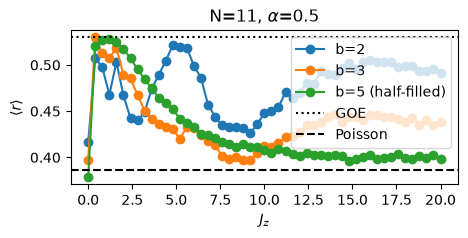

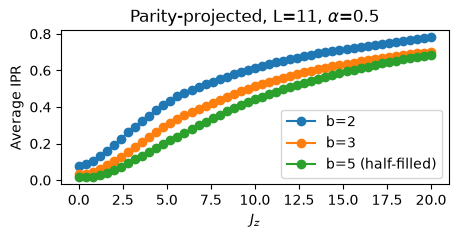

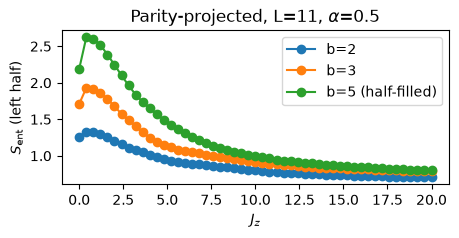

In [9]:
import pandas as pd
import os

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

output_dir = "MBL"

L = 11
alpha = 0.5
W = 0.2

sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

df = pd.read_csv(sweep_file)
page = pd.read_csv(page_file).set_index("n_up")["S_max_estimate"]

# n_up_values = sorted(df["n_up"].unique())

n_up_values =[2,3,L//2] #1,
# ------------------------------------------------------------
# Plot <r> for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=label)

plt.axhline(0.5307, linestyle=":", color="k", label="GOE")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"N={L}, $\alpha$={alpha}")
plt.legend()
plt.savefig("plt/r_vs_Jz_sectors.pdf")
plt.show()


# ------------------------------------------------------------
# Plot IPR for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=label)

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot entanglement entropy for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    line, = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=label)
    # matching-colored dashed reference line for this sector's Page estimate
    # plt.axhline(page[n_up], linestyle=":", color=line.get_color(), alpha=0.5)

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")  # (dotted = Page estimate per sector)
plt.legend()
plt.show()

### Same plot above for $\alpha=0.4, W=0.2, J_x=1$

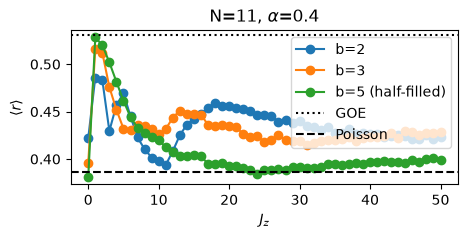

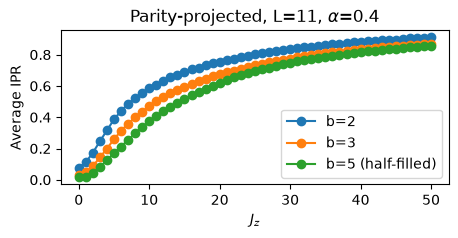

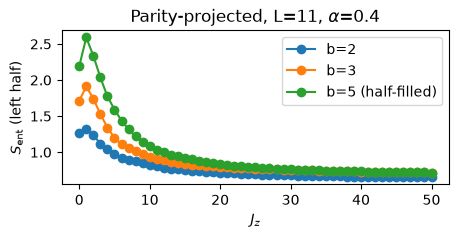

In [10]:
import pandas as pd
import os

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

output_dir = "MBL"

L = 11
alpha = 0.4
W = 0.2

sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
page_file = os.path.join(output_dir, f"page_estimates_L{L}_alpha{alpha}_W{W}.csv")

df = pd.read_csv(sweep_file)
page = pd.read_csv(page_file).set_index("n_up")["S_max_estimate"]

# n_up_values = sorted(df["n_up"].unique())

n_up_values =[2,3,L//2] #1,
# ------------------------------------------------------------
# Plot <r> for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=label)

plt.axhline(0.5307, linestyle=":", color="k", label="GOE")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"N={L}, $\alpha$={alpha}")
plt.legend()
plt.savefig("plt/r_vs_Jz_sectors.pdf")
plt.show()


# ------------------------------------------------------------
# Plot IPR for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=label)

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot entanglement entropy for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    line, = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=label)
    # matching-colored dashed reference line for this sector's Page estimate
    # plt.axhline(page[n_up], linestyle=":", color=line.get_color(), alpha=0.5)

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")  # (dotted = Page estimate per sector)
plt.legend()
plt.show()

### Same plot above for $\alpha=0.4, W=0.0, J_x=1$

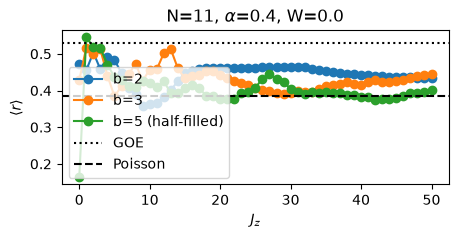

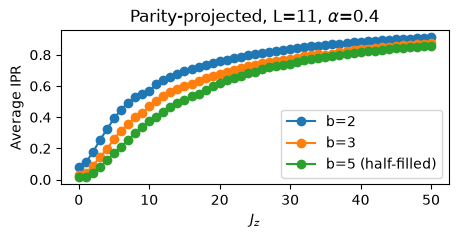

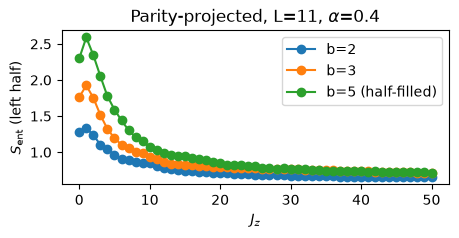

In [7]:
import pandas as pd
import os

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

output_dir = "MBL"

L = 11
alpha = 0.4
W = 0.0

sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
page_file = os.path.join(output_dir, f"page_estimates_L{L}_alpha{alpha}_W{W}.csv")

df = pd.read_csv(sweep_file)
page = pd.read_csv(page_file).set_index("n_up")["S_max_estimate"]

# n_up_values = sorted(df["n_up"].unique())

n_up_values =[2,3,L//2] #1,
# ------------------------------------------------------------
# Plot <r> for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=label)

plt.axhline(0.5307, linestyle=":", color="k", label="GOE")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"N={L}, $\alpha$={alpha}, W={W}")
plt.legend()
plt.savefig("plt/r_vs_Jz_sectors.pdf")
plt.show()


# ------------------------------------------------------------
# Plot IPR for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=label)

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot entanglement entropy for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    line, = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=label)
    # matching-colored dashed reference line for this sector's Page estimate
    # plt.axhline(page[n_up], linestyle=":", color=line.get_color(), alpha=0.5)

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")  # (dotted = Page estimate per sector)
plt.legend()
plt.show()

### Same plot above for $\alpha=0, W=0.2, Jx=1$

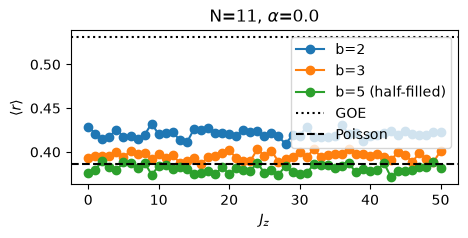

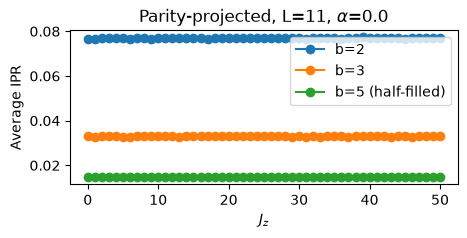

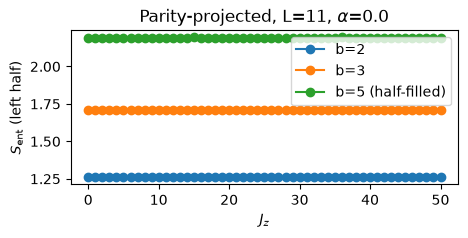

In [3]:
import pandas as pd
import os

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

output_dir = "MBL"

L = 11
alpha = 0.0
W = 0.2

sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
page_file = os.path.join(output_dir, f"page_estimates_L{L}_alpha{alpha}_W{W}.csv")

df = pd.read_csv(sweep_file)
page = pd.read_csv(page_file).set_index("n_up")["S_max_estimate"]

# n_up_values = sorted(df["n_up"].unique())

n_up_values =[2,3,L//2] #1,
# ------------------------------------------------------------
# Plot <r> for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=label)

plt.axhline(0.5307, linestyle=":", color="k", label="GOE")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"N={L}, $\alpha$={alpha}")
plt.legend()
plt.savefig("plt/r_vs_Jz_sectors.pdf")
plt.show()


# ------------------------------------------------------------
# Plot IPR for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=label)

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot entanglement entropy for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    line, = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=label)
    # matching-colored dashed reference line for this sector's Page estimate
    # plt.axhline(page[n_up], linestyle=":", color=line.get_color(), alpha=0.5)

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")  # (dotted = Page estimate per sector)
plt.legend()
plt.show()

### Same plot above for $\alpha=0, W=0.0, Jx=1$

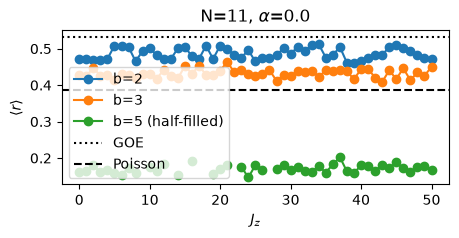

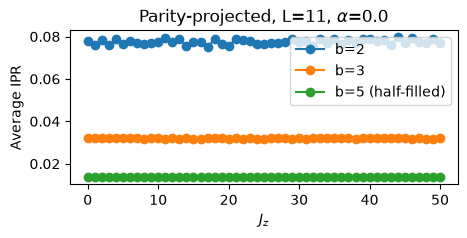

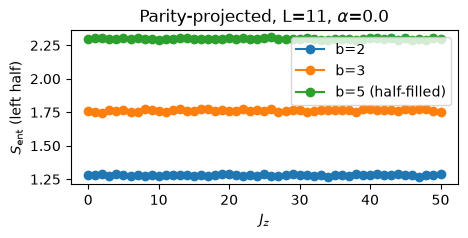

In [4]:
import pandas as pd
import os

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

output_dir = "MBL"

L = 11
alpha = 0.0
W = 0.0

sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
page_file = os.path.join(output_dir, f"page_estimates_L{L}_alpha{alpha}_W{W}.csv")

df = pd.read_csv(sweep_file)
page = pd.read_csv(page_file).set_index("n_up")["S_max_estimate"]

# n_up_values = sorted(df["n_up"].unique())

n_up_values =[2,3,L//2] #1,
# ------------------------------------------------------------
# Plot <r> for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=label)

plt.axhline(0.5307, linestyle=":", color="k", label="GOE")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"N={L}, $\alpha$={alpha}")
plt.legend()
plt.savefig("plt/r_vs_Jz_sectors.pdf")
plt.show()


# ------------------------------------------------------------
# Plot IPR for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=label)

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot entanglement entropy for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    line, = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=label)
    # matching-colored dashed reference line for this sector's Page estimate
    # plt.axhline(page[n_up], linestyle=":", color=line.get_color(), alpha=0.5)

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")  # (dotted = Page estimate per sector)
plt.legend()
plt.show()

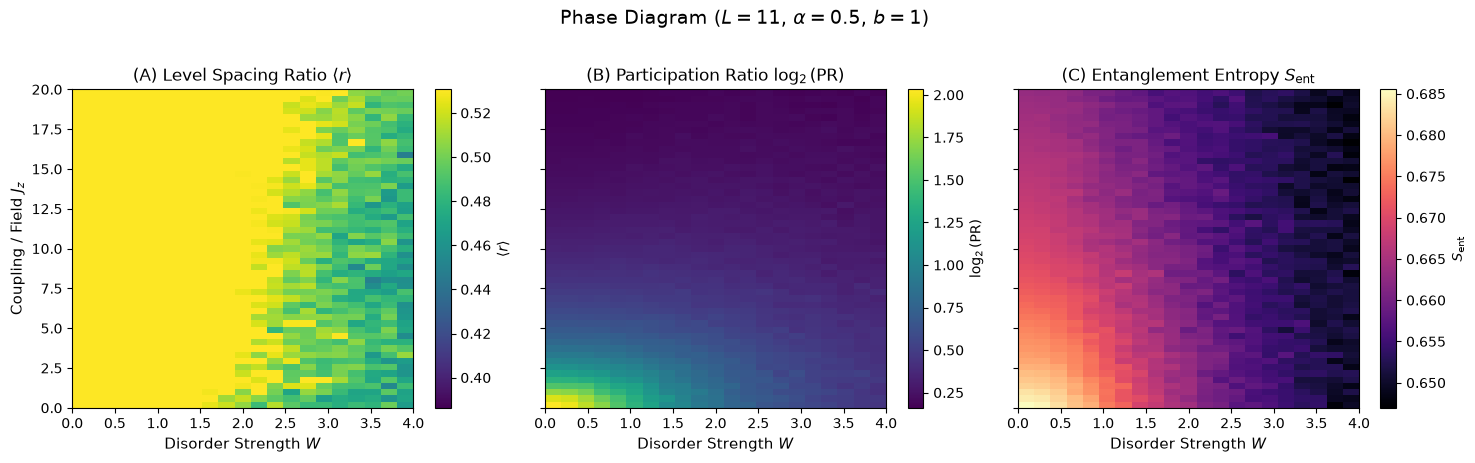

In [ ]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Configuration & Data Loading
# ============================================================
output_dir = "MBL"
L = 11
alpha = 0.5
n_up_target = 1  # Focus on specific sector (1, 2, 3, or L//2 for half-filling)

# Search for all W files matching L and alpha
file_pattern = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W*.csv")
files = glob.glob(file_pattern)

dfs = []
for fname in files:
    # Extract W value directly from file name to ensure precise float parsing
    match = re.search(r"W([0-9.]+)\.csv", fname)
    if match:
        df_temp = pd.read_csv(fname)
        dfs.append(df_temp)

if not dfs:
    raise FileNotFoundError(f"No sweep CSV files found matching {file_pattern}")

# Combine all W data into a single DataFrame
full_df = pd.concat(dfs, ignore_index=True)

# Force numeric types across all numerical columns (cleans string/object dtypes)
numeric_cols = ["L", "n_up", "Jz", "W", "r_mean", "ipr_mean", "S_mean"]
for col in numeric_cols:
    if col in full_df.columns:
        full_df[col] = pd.to_numeric(full_df[col], errors="coerce")

full_df["W"] = full_df["W"].round(4)
full_df["Jz"] = full_df["Jz"].round(4)

# Drop any NaN rows generated by unparsed headers and filter for target sector
sector_df = full_df[full_df["n_up"] == n_up_target].dropna(subset=["Jz", "W", "r_mean", "ipr_mean", "S_mean"])
# ============================================================
# 2. Pivot into 2D Grids & Reindex onto Clean Uniform Grid
# ============================================================
# Round float keys to remove machine precision noise
sector_df["W"] = sector_df["W"].round(4)
sector_df["Jz"] = sector_df["Jz"].round(4)

grid_r = sector_df.pivot(index="Jz", columns="W", values="r_mean").sort_index(ascending=True)
grid_ipr = sector_df.pivot(index="Jz", columns="W", values="ipr_mean").sort_index(ascending=True)
grid_S = sector_df.pivot(index="Jz", columns="W", values="S_mean").sort_index(ascending=True)

# Calculate log2(PR)
grid_log2_PR = np.log2(1.0 / grid_ipr)

# Create explicit clean 1D arrays for axes
W_vals = grid_r.columns.values.astype(float)
Jz_vals = grid_r.index.values.astype(float)

# ============================================================
# 3. Plot Phase Diagrams (Using imshow to avoid pcolormesh seams)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

# Define exact spatial bounds [xmin, xmax, ymin, ymax]
extent = [W_vals.min(), W_vals.max(), Jz_vals.min(), Jz_vals.max()]

# --- (A) r-index Heatmap ---
im0 = axes[0].imshow(
    grid_r.values, 
    origin="lower", 
    aspect="auto", 
    extent=extent,
    cmap="viridis", vmin=0.3863, vmax=0.5307,
    interpolation="nearest"
)
axes[0].set_title(r"(A) Level Spacing Ratio $\langle r \rangle$", fontsize=12)
axes[0].set_xlabel(r"Disorder Strength $W$", fontsize=11)
axes[0].set_ylabel(r"Coupling / Field $J_z$", fontsize=11)
cbar0 = fig.colorbar(im0, ax=axes[0])
cbar0.set_label(r"$\langle r \rangle$", fontsize=10)

# --- (B) log2(PR) Heatmap ---
im1 = axes[1].imshow(
    grid_log2_PR.values, 
    origin="lower", 
    aspect="auto", 
    extent=extent,
    cmap="viridis",
    interpolation="nearest"
)
axes[1].set_title(r"(B) Participation Ratio $\log_2(\text{PR})$", fontsize=12)
axes[1].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar1 = fig.colorbar(im1, ax=axes[1])
cbar1.set_label(r"$\log_2(\text{PR})$", fontsize=10)

# --- (C) Entanglement Entropy Heatmap ---
im2 = axes[2].imshow(
    grid_S.values, 
    origin="lower", 
    aspect="auto", 
    extent=extent,
    cmap="magma",
    interpolation="nearest"
)
axes[2].set_title(r"(C) Entanglement Entropy $S_{\rm ent}$", fontsize=12)
axes[2].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar2 = fig.colorbar(im2, ax=axes[2])
cbar2.set_label(r"$S_{\rm ent}$", fontsize=10)

fig.suptitle(f"Phase Diagram ($L={L}$, $\\alpha={alpha}$, $b={n_up_target}$)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

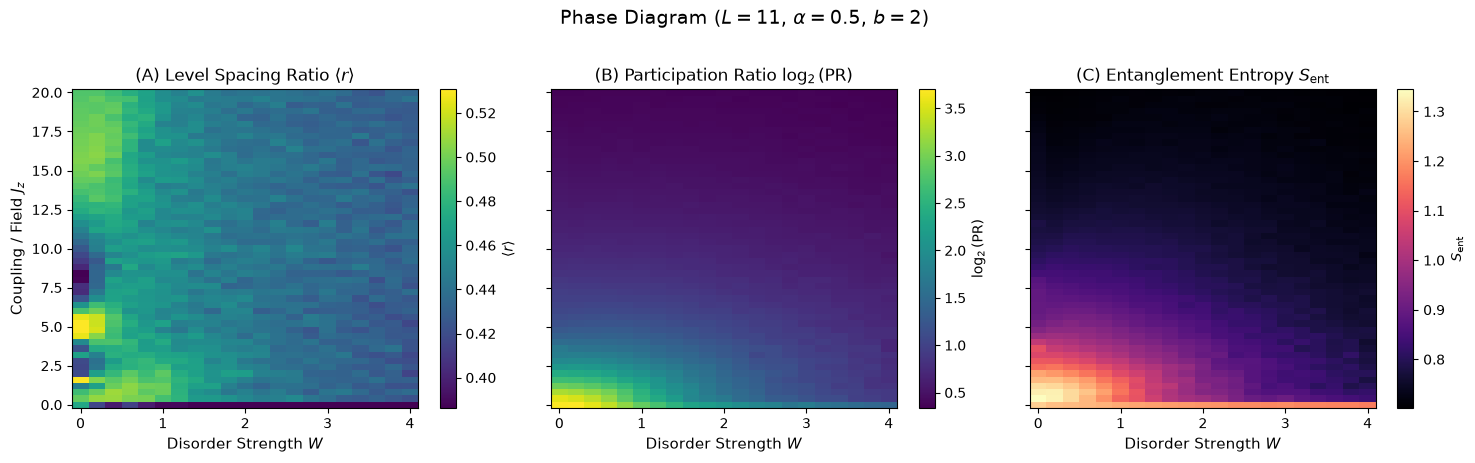

In [75]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Configuration & Data Loading
# ============================================================
output_dir = "MBL"
L = 11
alpha = 0.5
n_up_target = 2  # Focus on specific sector (1, 2, 3, or L//2 for half-filling)

# Search for all W files matching L and alpha
file_pattern = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W*.csv")
files = glob.glob(file_pattern)

dfs = []
for fname in files:
    # Extract W value directly from file name to ensure precise float parsing
    match = re.search(r"W([0-9.]+)\.csv", fname)
    if match:
        df_temp = pd.read_csv(fname)
        dfs.append(df_temp)

if not dfs:
    raise FileNotFoundError(f"No sweep CSV files found matching {file_pattern}")

# Combine all W data into a single DataFrame
full_df = pd.concat(dfs, ignore_index=True)

# Force numeric types across all numerical columns (cleans string/object dtypes)
numeric_cols = ["L", "n_up", "Jz", "W", "r_mean", "ipr_mean", "S_mean"]
for col in numeric_cols:
    if col in full_df.columns:
        full_df[col] = pd.to_numeric(full_df[col], errors="coerce")

# Drop any NaN rows generated by unparsed headers and filter for target sector
sector_df = full_df[full_df["n_up"] == n_up_target].dropna(subset=["Jz", "W", "r_mean", "ipr_mean", "S_mean"])

# ============================================================
# 2. Pivot into 2D Grids (Rows = Jz, Cols = W)
# ============================================================
grid_r = sector_df.pivot(index="Jz", columns="W", values="r_mean").sort_index(ascending=True).astype(float)
grid_ipr = sector_df.pivot(index="Jz", columns="W", values="ipr_mean").sort_index(ascending=True).astype(float)
grid_S = sector_df.pivot(index="Jz", columns="W", values="S_mean").sort_index(ascending=True).astype(float)

# Calculate Participation Ratio PR = 1 / IPR and take log2(PR)
grid_log2_PR = np.log2(1.0 / grid_ipr)

# Extract axis values as pure 64-bit float arrays
W_vals = grid_r.columns.values.astype(float)
Jz_vals = grid_r.index.values.astype(float)

# ============================================================
# 3. Plot Phase Diagrams (Heatmaps)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

# --- (A) r-index Heatmap ---
im0 = axes[0].pcolormesh(
    W_vals, Jz_vals, grid_r.values, 
    cmap="viridis", vmin=0.3863, vmax=0.5307, shading="nearest"
)
axes[0].set_title(r"(A) Level Spacing Ratio $\langle r \rangle$", fontsize=12)
axes[0].set_xlabel(r"Disorder Strength $W$", fontsize=11)
axes[0].set_ylabel(r"Coupling / Field $J_z$", fontsize=11)
cbar0 = fig.colorbar(im0, ax=axes[0])
cbar0.set_label(r"$\langle r \rangle$", fontsize=10)

# Optional phase boundary contour line at r ≈ 0.46
# axes[0].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (B) log2(PR) Heatmap ---
im1 = axes[1].pcolormesh(
    W_vals, Jz_vals, grid_log2_PR.values, 
    cmap="viridis", shading="nearest"
)
axes[1].set_title(r"(B) Participation Ratio $\log_2(\text{PR})$", fontsize=12)
axes[1].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar1 = fig.colorbar(im1, ax=axes[1])
cbar1.set_label(r"$\log_2(\text{PR})$", fontsize=10)

# --- (C) Entanglement Entropy Heatmap ---
im2 = axes[2].pcolormesh(
    W_vals, Jz_vals, grid_S.values, 
    cmap="magma", shading="nearest"
)
axes[2].set_title(r"(C) Entanglement Entropy $S_{\rm ent}$", fontsize=12)
axes[2].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar2 = fig.colorbar(im2, ax=axes[2])
cbar2.set_label(r"$S_{\rm ent}$", fontsize=10)

fig.suptitle(f"Phase Diagram ($L={L}$, $\\alpha={alpha}$, $b={n_up_target}$)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

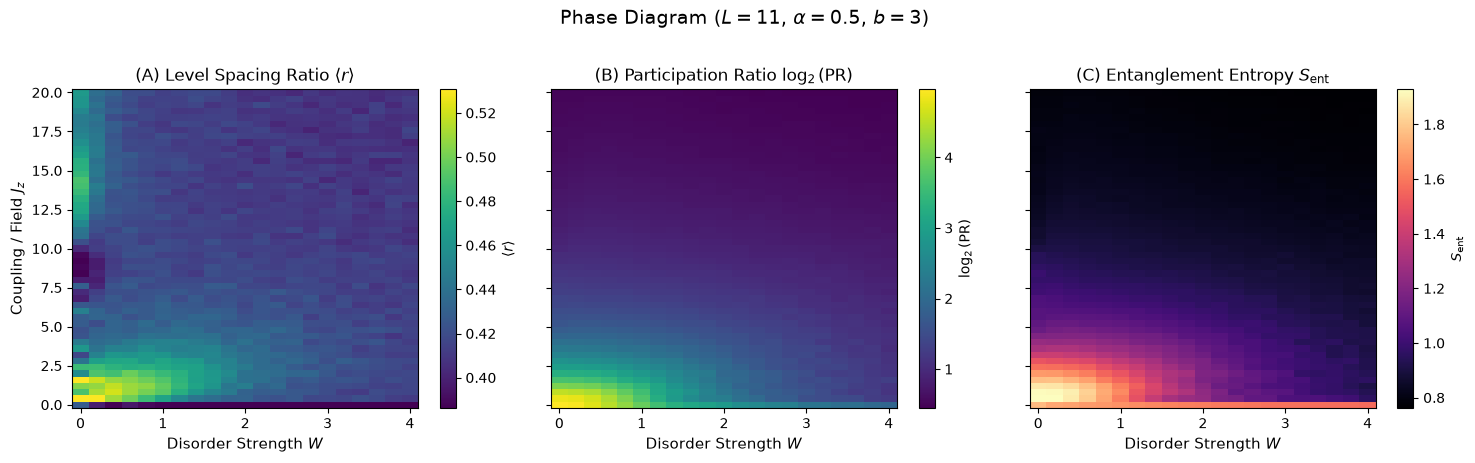

In [76]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Configuration & Data Loading
# ============================================================
output_dir = "MBL"
L = 11
alpha = 0.5
n_up_target = 3  # Focus on specific sector (1, 2, 3, or L//2 for half-filling)

# Search for all W files matching L and alpha
file_pattern = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W*.csv")
files = glob.glob(file_pattern)

dfs = []
for fname in files:
    # Extract W value directly from file name to ensure precise float parsing
    match = re.search(r"W([0-9.]+)\.csv", fname)
    if match:
        df_temp = pd.read_csv(fname)
        dfs.append(df_temp)

if not dfs:
    raise FileNotFoundError(f"No sweep CSV files found matching {file_pattern}")

# Combine all W data into a single DataFrame
full_df = pd.concat(dfs, ignore_index=True)

# Force numeric types across all numerical columns (cleans string/object dtypes)
numeric_cols = ["L", "n_up", "Jz", "W", "r_mean", "ipr_mean", "S_mean"]
for col in numeric_cols:
    if col in full_df.columns:
        full_df[col] = pd.to_numeric(full_df[col], errors="coerce")

# Drop any NaN rows generated by unparsed headers and filter for target sector
sector_df = full_df[full_df["n_up"] == n_up_target].dropna(subset=["Jz", "W", "r_mean", "ipr_mean", "S_mean"])

# ============================================================
# 2. Pivot into 2D Grids (Rows = Jz, Cols = W)
# ============================================================
grid_r = sector_df.pivot(index="Jz", columns="W", values="r_mean").sort_index(ascending=True).astype(float)
grid_ipr = sector_df.pivot(index="Jz", columns="W", values="ipr_mean").sort_index(ascending=True).astype(float)
grid_S = sector_df.pivot(index="Jz", columns="W", values="S_mean").sort_index(ascending=True).astype(float)

# Calculate Participation Ratio PR = 1 / IPR and take log2(PR)
grid_log2_PR = np.log2(1.0 / grid_ipr)

# Extract axis values as pure 64-bit float arrays
W_vals = grid_r.columns.values.astype(float)
Jz_vals = grid_r.index.values.astype(float)

# ============================================================
# 3. Plot Phase Diagrams (Heatmaps)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

# --- (A) r-index Heatmap ---
im0 = axes[0].pcolormesh(
    W_vals, Jz_vals, grid_r.values, 
    cmap="viridis", vmin=0.3863, vmax=0.5307, shading="nearest"
)
axes[0].set_title(r"(A) Level Spacing Ratio $\langle r \rangle$", fontsize=12)
axes[0].set_xlabel(r"Disorder Strength $W$", fontsize=11)
axes[0].set_ylabel(r"Coupling / Field $J_z$", fontsize=11)
cbar0 = fig.colorbar(im0, ax=axes[0])
cbar0.set_label(r"$\langle r \rangle$", fontsize=10)

# Optional phase boundary contour line at r ≈ 0.46
# axes[0].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (B) log2(PR) Heatmap ---
im1 = axes[1].pcolormesh(
    W_vals, Jz_vals, grid_log2_PR.values, 
    cmap="viridis", shading="nearest"
)
axes[1].set_title(r"(B) Participation Ratio $\log_2(\text{PR})$", fontsize=12)
axes[1].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar1 = fig.colorbar(im1, ax=axes[1])
cbar1.set_label(r"$\log_2(\text{PR})$", fontsize=10)

# --- (C) Entanglement Entropy Heatmap ---
im2 = axes[2].pcolormesh(
    W_vals, Jz_vals, grid_S.values, 
    cmap="magma", shading="nearest"
)
axes[2].set_title(r"(C) Entanglement Entropy $S_{\rm ent}$", fontsize=12)
axes[2].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar2 = fig.colorbar(im2, ax=axes[2])
cbar2.set_label(r"$S_{\rm ent}$", fontsize=10)

fig.suptitle(f"Phase Diagram ($L={L}$, $\\alpha={alpha}$, $b={n_up_target}$)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

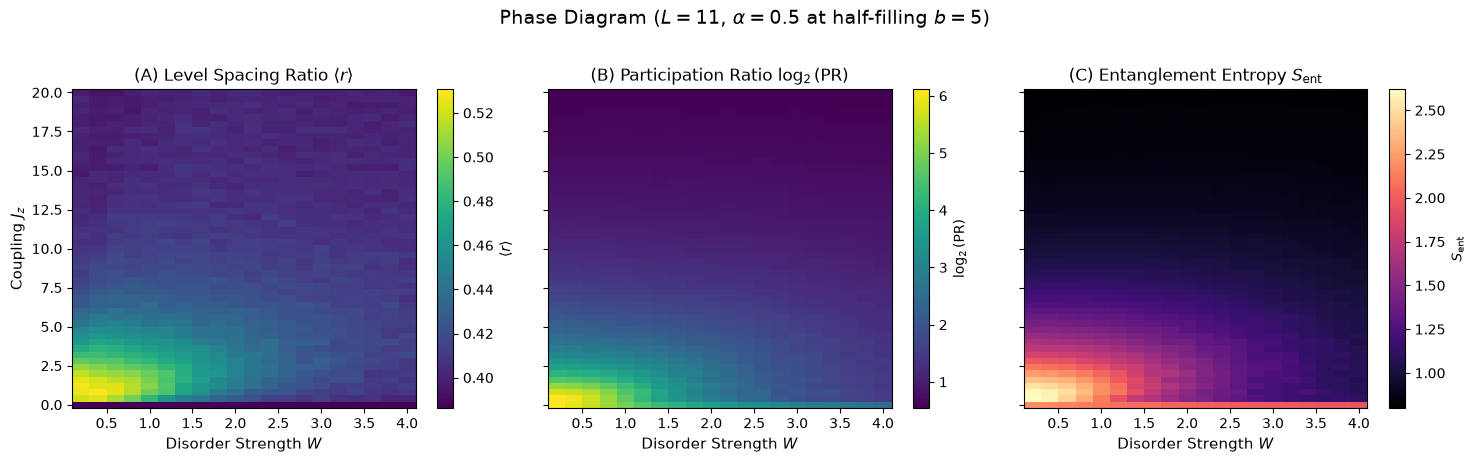

In [84]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Configuration & Data Loading
# ============================================================
output_dir = "MBL"
L = 11
alpha = 0.5
n_up_target = 5  # Focus on specific sector (1, 2, 3, or L//2 for half-filling)

# Search for all W files matching L and alpha
file_pattern = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W*.csv")
files = glob.glob(file_pattern)

dfs = []
for fname in files:
    # Extract W value directly from file name to ensure precise float parsing
    match = re.search(r"W([0-9.]+)\.csv", fname)
    if match:
        df_temp = pd.read_csv(fname)
        dfs.append(df_temp)

if not dfs:
    raise FileNotFoundError(f"No sweep CSV files found matching {file_pattern}")

# Combine all W data into a single DataFrame
full_df = pd.concat(dfs, ignore_index=True)

# Force numeric types across all numerical columns (cleans string/object dtypes)
numeric_cols = ["L", "n_up", "Jz", "W", "r_mean", "ipr_mean", "S_mean"]
for col in numeric_cols:
    if col in full_df.columns:
        full_df[col] = pd.to_numeric(full_df[col], errors="coerce")

# Drop any NaN rows generated by unparsed headers and filter for target sector
sector_df = full_df[full_df["n_up"] == n_up_target].dropna(subset=["Jz", "W", "r_mean", "ipr_mean", "S_mean"])

# ============================================================
# 2. Pivot into 2D Grids (Rows = Jz, Cols = W)
# ============================================================
grid_r = sector_df.pivot(index="Jz", columns="W", values="r_mean").sort_index(ascending=True).astype(float)
grid_ipr = sector_df.pivot(index="Jz", columns="W", values="ipr_mean").sort_index(ascending=True).astype(float)
grid_S = sector_df.pivot(index="Jz", columns="W", values="S_mean").sort_index(ascending=True).astype(float)

# Calculate Participation Ratio PR = 1 / IPR and take log2(PR)
grid_log2_PR = np.log2(1.0 / grid_ipr)

# Extract axis values as pure 64-bit float arrays
W_vals = grid_r.columns.values.astype(float)
Jz_vals = grid_r.index.values.astype(float)

# ============================================================
# 3. Plot Phase Diagrams (Heatmaps)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
# --- (A) r-index Heatmap ---
im0 = axes[0].pcolormesh(
    W_vals, Jz_vals, grid_r.values, 
    cmap="viridis", vmin=0.3863, vmax=0.5307, shading="nearest",
    rasterized=True
)
axes[0].set_title(r"(A) Level Spacing Ratio $\langle r \rangle$", fontsize=12)
axes[0].set_xlabel(r"Disorder Strength $W$", fontsize=11)
axes[0].set_ylabel(r"Coupling $J_z$", fontsize=11)
cbar0 = fig.colorbar(im0, ax=axes[0])
cbar0.set_label(r"$\langle r \rangle$", fontsize=10)

# --- (B) log2(PR) Heatmap ---
im1 = axes[1].pcolormesh(
    W_vals, Jz_vals, grid_log2_PR.values, 
    cmap="viridis", shading="nearest",
    rasterized=True
)
axes[1].set_title(r"(B) Participation Ratio $\log_2(\text{PR})$", fontsize=12)
axes[1].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar1 = fig.colorbar(im1, ax=axes[1])
cbar1.set_label(r"$\log_2(\text{PR})$", fontsize=10)

# --- (C) Entanglement Entropy Heatmap ---
im2 = axes[2].pcolormesh(
    W_vals, Jz_vals, grid_S.values, 
    cmap="magma", shading="nearest",
    rasterized=True
)
axes[2].set_title(r"(C) Entanglement Entropy $S_{\rm ent}$", fontsize=12)
axes[2].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar2 = fig.colorbar(im2, ax=axes[2])
cbar2.set_label(r"$S_{\rm ent}$", fontsize=10)

fig.suptitle(f"Phase Diagram ($L={L}$, $\\alpha={alpha}$ at half-filling $b={n_up_target}$)", fontsize=14, y=1.02)
plt.tight_layout()

# Save with rasterized resolution set
plt.savefig("plt/HeatmapErgodicToMBL.pdf", dpi=300, bbox_inches="tight")
plt.show()

### N Sweep

In [5]:
list(range(10, 51, 5))
[10, 15, 20, 25, 30, 35, 40, 45, 50]

[10, 15, 20, 25, 30, 35, 40, 45, 50]

In [6]:
import csv
import os
import numpy as np
from itertools import combinations

# ============================================================
# Jz sweep across multiple system sizes L
# Fixed parameters: alpha = 0.5, W = 0.2, Jx = 1.0
# ============================================================

# Define list of system sizes L to sweep over
L_list = list(range(10, 101, 5))

alpha = 0.4     # fixed long-range exponent
W = 0.0         # fixed disorder strength
Jx = 1.0        # fixed transverse coupling
Jz_values = [20]; #np.linspace(0.0, 20.0, 11)  # adjust range/points as needed

output_dir = "MBL/b2sector"
os.makedirs(output_dir, exist_ok=True)

fieldnames = ["n_up", "Jz", "alpha", "Jx", "W", "L",
              "r_mean", "r_std", "ipr_mean", "ipr_std",
              "S_mean", "S_std", "off_norm"]

for L in L_list:
    # Set sector range per L (e.g., 1, 2, 3, and half-filling)
    n_up_values = sorted(list(set([2]))) #1, 2, 3, 2, 3, L // 2
    
    output_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    
    print(f"\n--- Starting sweep for L = {L} (W = {W}, alpha = {alpha}) ---")

    with open(output_file, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for n_up in n_up_values:
            for Jz in Jz_values:

                r_mean, r_std, ipr_mean, ipr_std, S_mean, S_std, off_norm = disorder_average(
                    L=L, n_up=n_up, W=W, realizations=1, Jz=Jz, alpha=alpha, Jx=Jx, frac=1
                )

                row = {
                    "n_up": n_up, "Jz": Jz, "alpha": alpha, "Jx": Jx, "W": W, "L": L,
                    "r_mean": r_mean, "r_std": r_std,
                    "ipr_mean": ipr_mean, "ipr_std": ipr_std,
                    "S_mean": S_mean, "S_std": S_std,
                    "off_norm": off_norm,
                }

                writer.writerow(row)
                f.flush()

                print(f"[L={L}] n_up={n_up}  Jz={Jz:.2f}  <r>={r_mean:.4f}  "
                      f"IPR={ipr_mean:.4f}  S_ent={S_mean:.4f}  max off-block norm={off_norm:.2e}")

    # Save Page estimates specific to this L
    cut = L // 2
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    with open(page_file, "w", newline="") as f:
        writer_page = csv.DictWriter(f, fieldnames=["n_up", "S_max_estimate"])
        writer_page.writeheader()

        for n_up in n_up_values:
            S_max = np.log(min(
                sum(1 for _ in combinations(range(cut), min(n_up, cut))),
                sum(1 for _ in combinations(range(L - cut), min(n_up, L - cut)))
            ) + 1)
            writer_page.writerow({"n_up": n_up, "S_max_estimate": S_max})

print(f"\nSweep complete. All results written to '{output_dir}/'")


--- Starting sweep for L = 10 (W = 0.0, alpha = 0.4) ---
[L=10] n_up=2  Jz=20.00  <r>=0.4302  IPR=0.7753  S_ent=0.6729  max off-block norm=3.46e-14

--- Starting sweep for L = 15 (W = 0.0, alpha = 0.4) ---
[L=15] n_up=2  Jz=20.00  <r>=0.4314  IPR=0.7176  S_ent=0.7501  max off-block norm=2.49e-13

--- Starting sweep for L = 20 (W = 0.0, alpha = 0.4) ---
[L=20] n_up=2  Jz=20.00  <r>=0.4164  IPR=0.6675  S_ent=0.7777  max off-block norm=4.55e-13

--- Starting sweep for L = 25 (W = 0.0, alpha = 0.4) ---
[L=25] n_up=2  Jz=20.00  <r>=0.3843  IPR=0.6439  S_ent=0.8018  max off-block norm=6.82e-13

--- Starting sweep for L = 30 (W = 0.0, alpha = 0.4) ---
[L=30] n_up=2  Jz=20.00  <r>=0.3562  IPR=0.6187  S_ent=0.7971  max off-block norm=1.59e-12

--- Starting sweep for L = 35 (W = 0.0, alpha = 0.4) ---
[L=35] n_up=2  Jz=20.00  <r>=0.4118  IPR=0.5968  S_ent=0.8081  max off-block norm=1.36e-12

--- Starting sweep for L = 40 (W = 0.0, alpha = 0.4) ---
[L=40] n_up=2  Jz=20.00  <r>=0.3829  IPR=0.5820 

#### b=1 vary N, and Jz (W=0.2 and W=0)

    N     r_numeric(Jz=20.0)    r_theory (Jx=0)
   10                 0.5354             0.5182
   20                 0.7274             0.6774
   30                 0.7692             0.7506
   50                 0.8381             0.8231
   80                 0.8888             0.8732
  100                 0.9048             0.8922
  200                 0.9448             0.9361
  300                 0.9604             0.9534


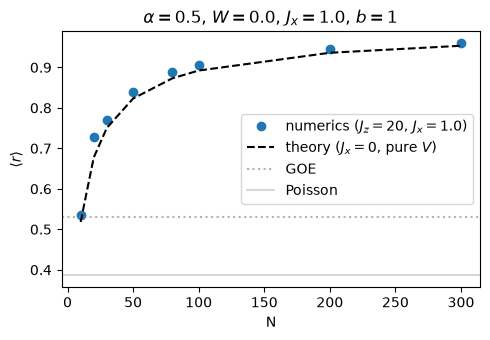

In [16]:
import numpy as np

def epsilon_k(k, L, alpha):
    s1 = np.sum(1.0 / np.arange(1, k)**alpha) if k > 1 else 0
    s2 = np.sum(1.0 / np.arange(1, L - k + 1)**alpha) if k < L else 0
    return s1 + s2

def gap_ratio_from_levels(levels):
    levels = np.sort(levels)
    gaps = np.diff(levels)
    gaps = gaps[gaps > 1e-12]
    r = np.minimum(gaps[1:], gaps[:-1]) / np.maximum(gaps[1:], gaps[:-1])
    return np.mean(r)

def picket_fence_r(L, alpha):
    ks = np.arange(1, L + 1)
    V = np.array([epsilon_k(k, L, alpha) for k in ks])
    d = np.abs(ks - (L + 1) / 2.0)
    _, unique_idx = np.unique(np.round(d, 9), return_index=True)
    V_folded = V[unique_idx]
    return gap_ratio_from_levels(V_folded)

# ------------------------------------------------------------
# Compare theory (J_x=0, pure V) vs numerics at largest Jz
# ------------------------------------------------------------
Jx = 1.0  # from your sweep script

Jz_compare = data_dict[L_values[0]]["Jz"].max()

print(f"{'N':>5} {'r_numeric(Jz={:.1f})'.format(Jz_compare):>22} {'r_theory (Jx=0)':>18}")
r_num_list, r_th_list = [], []
for L in L_values:
    sub = data_dict[L]
    row = sub.iloc[(sub["Jz"] - Jz_compare).abs().argmin()]
    r_num = row["r_mean"]
    r_th = picket_fence_r(L, alpha)
    r_num_list.append(r_num)
    r_th_list.append(r_th)
    print(f"{L:5d} {r_num:22.4f} {r_th:18.4f}")

plt.figure(figsize=(5, 3.5))
plt.plot(L_values, r_num_list, 'o', label=rf'numerics ($J_z={Jz_compare:.0f}$, $J_x={Jx}$)')
plt.plot(L_values, r_th_list, '--', color='k', label=r'theory ($J_x=0$, pure $V$)')
plt.axhline(0.5307, ls=':', color='gray', alpha=0.6, label='GOE')
plt.axhline(0.3863, ls='-', color='gray', alpha=0.3, label='Poisson')
plt.xlabel("N")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"$\alpha={alpha}$, $W={W}$, $J_x={Jx}$, $b={n_up}$"
)
plt.legend()
plt.tight_layout()
plt.savefig("plt/picket_fence_check.pdf")
plt.show()

   10  r_mean=0.5556
   20  r_mean=0.4808
   30  r_mean=0.3963
   50  r_mean=0.3938
   80  r_mean=0.3966
  100  r_mean=0.3898


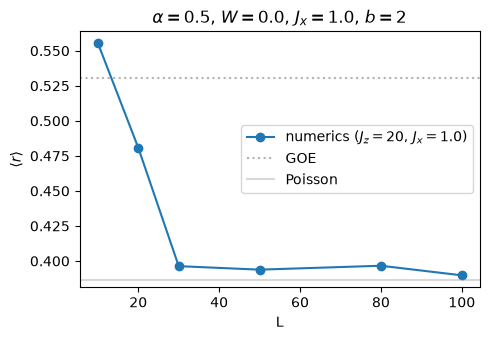

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import os

L_values = [10, 20, 30, 50, 80, 100]
alpha = 0.5
W = 0.0
Jx = 1.0
n_up = 2
output_dir = "MBL/b2sector"

data_dict = {}
for L in L_values:
    path = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    df = pd.read_csv(path)
    data_dict[L] = df[df["n_up"] == n_up].reset_index(drop=True)

Jz_compare = data_dict[L_values[0]]["Jz"].max()

r_num_list = []
for L in L_values:
    sub = data_dict[L]
    row = sub.iloc[(sub["Jz"] - Jz_compare).abs().argmin()]
    r_num_list.append(row["r_mean"])
    print(f"{L:5d}  r_mean={row['r_mean']:.4f}")

os.makedirs("plt", exist_ok=True)

plt.figure(figsize=(5, 3.5))
plt.plot(L_values, r_num_list, 'o-', label=rf'numerics ($J_z={Jz_compare:.0f}$, $J_x={Jx}$)')
plt.axhline(0.5307, ls=':', color='gray', alpha=0.6, label='GOE')
plt.axhline(0.3863, ls='-', color='gray', alpha=0.3, label='Poisson')
plt.xlabel("L")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"$\alpha={alpha}$, $W={W}$, $J_x={Jx}$, $b={n_up}$")
plt.legend()
plt.tight_layout()
plt.savefig("plt/b2_gap_ratio_vs_L.pdf")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

L_values = [10, 20, 30, 50, 80, 100]
alpha = 0.5
W = 0.0
Jx = 1.0
n_up = 3
output_dir = "MBL/b3sector"

data_dict = {}
for L in L_values:
    path = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    df = pd.read_csv(path)
    data_dict[L] = df[df["n_up"] == n_up].reset_index(drop=True)

Jz_compare = data_dict[L_values[0]]["Jz"].max()

r_num_list = []
for L in L_values:
    sub = data_dict[L]
    row = sub.iloc[(sub["Jz"] - Jz_compare).abs().argmin()]
    r_num_list.append(row["r_mean"])
    print(f"{L:5d}  r_mean={row['r_mean']:.4f}")

os.makedirs("plt", exist_ok=True)

plt.figure(figsize=(5, 3.5))
plt.plot(L_values, r_num_list, 'o-', label=rf'numerics ($J_z={Jz_compare:.0f}$, $J_x={Jx}$)')
plt.axhline(0.5307, ls=':', color='gray', alpha=0.6, label='GOE')
plt.axhline(0.3863, ls='-', color='gray', alpha=0.3, label='Poisson')
plt.xlabel("L")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"$\alpha={alpha}$, $W={W}$, $J_x={Jx}$, $b={n_up}$")
plt.legend()
plt.tight_layout()
plt.savefig("plt/b3_gap_ratio_vs_L.pdf")
plt.show()

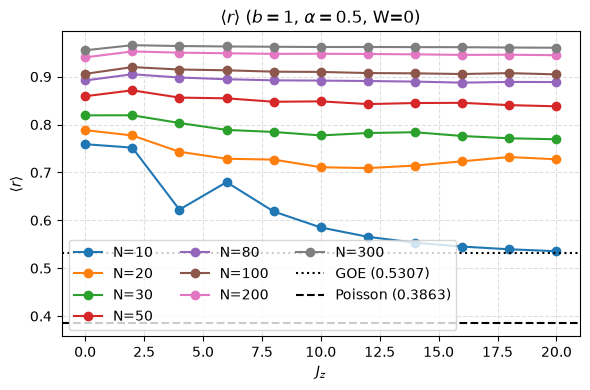

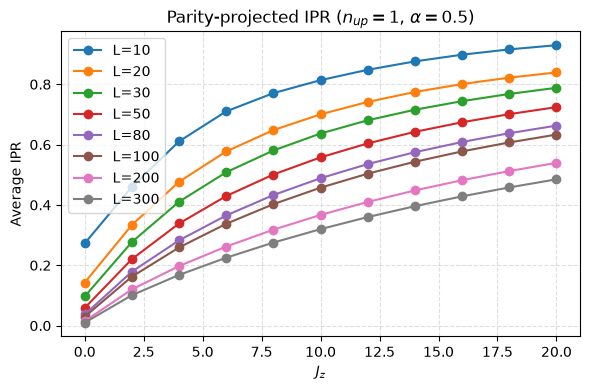

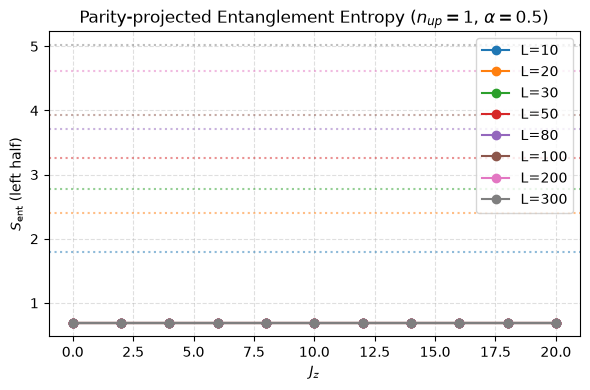

In [6]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL/b1sector"
L_values = [10, 20, 30, 50, 80, 100, 200, 300]
alpha = 0.5
W = 0.0
n_up = 1

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"N={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"$\langle r\rangle$ ($b={n_up}$, $\alpha={alpha}$, W=0)"
)
plt.legend(ncol=3)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("plt/r_vs_Jz_b1sector.pdf")
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

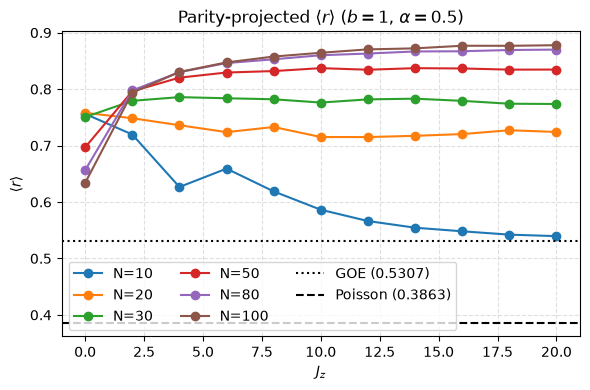

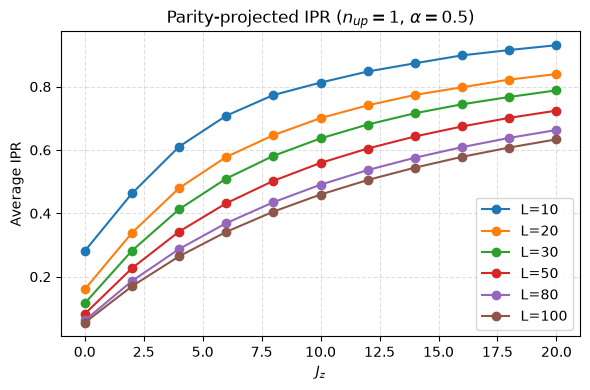

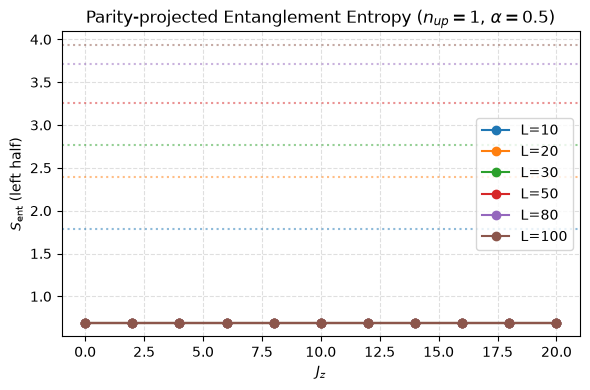

In [27]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL/b1sector"
L_values = [10, 20, 30, 50, 80, 100]
alpha = 0.5
W = 0.2
n_up = 1

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"N={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($b={n_up}$, $\alpha={alpha}$)"
)
plt.legend(ncol=3)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("plt/r_vs_Jz_b1sector.pdf")
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

#### W=0.2

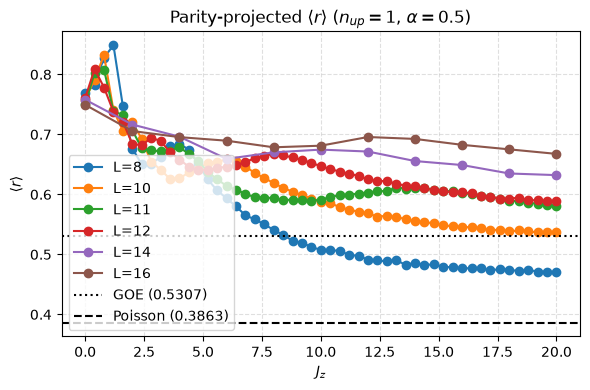

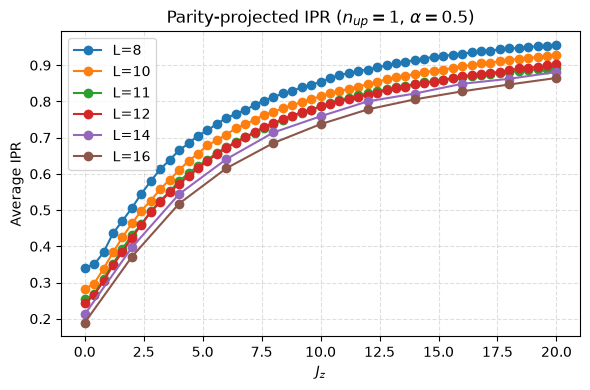

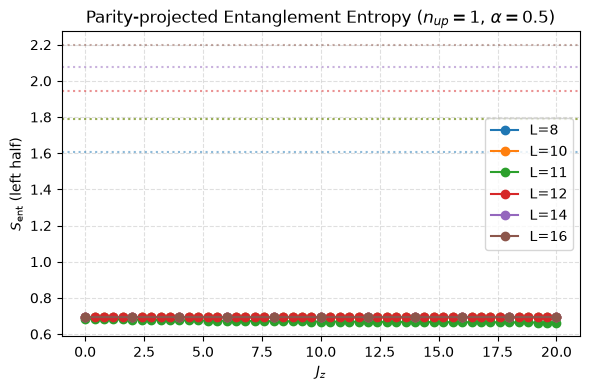

In [22]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [8, 10, 11, 12, 14, 16]
alpha = 0.5
W = 0.2
n_up = 1

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

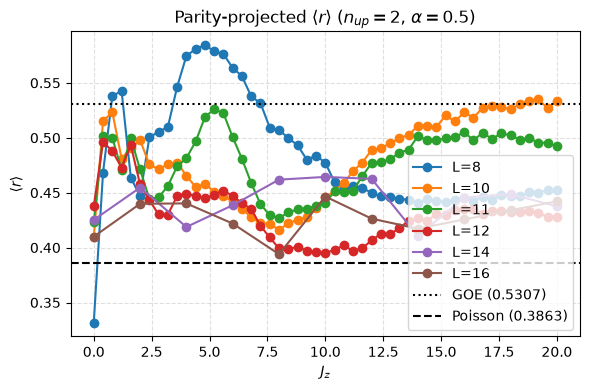

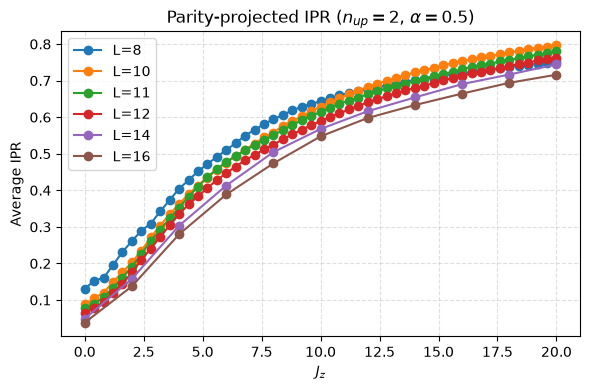

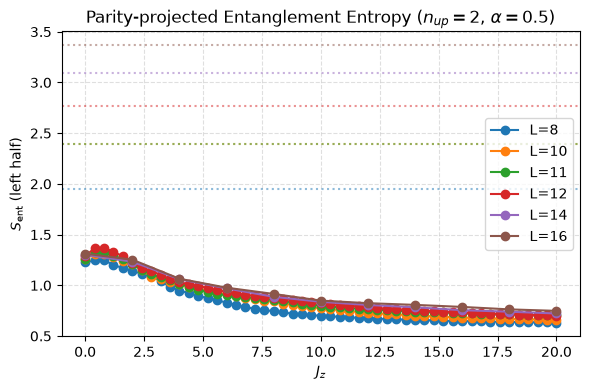

In [23]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [8, 10, 11, 12, 14, 16]
alpha = 0.5
W = 0.2
n_up = 2

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

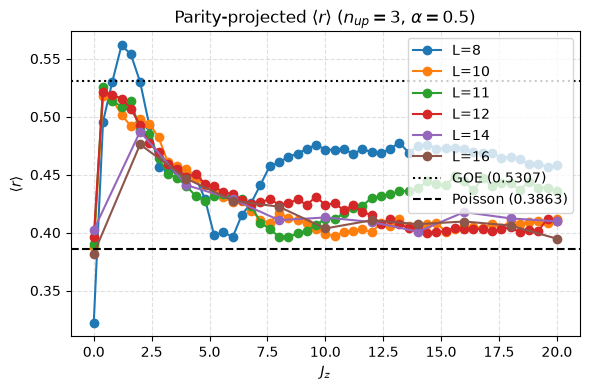

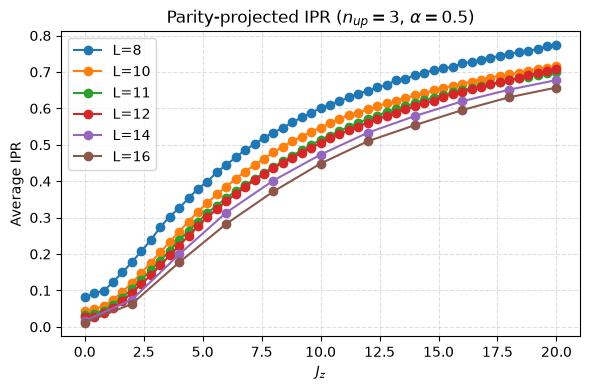

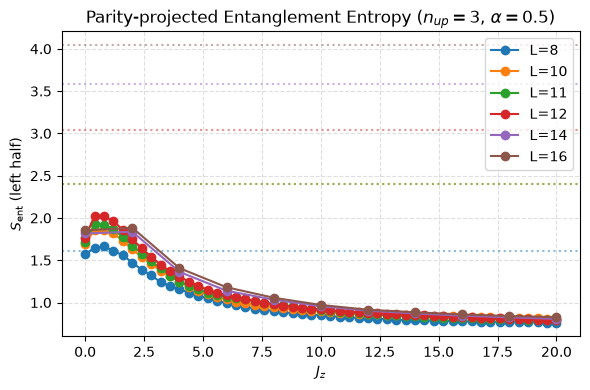

In [24]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [8, 10, 11, 12, 14, 16]
alpha = 0.5
W = 0.2
n_up = 3

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

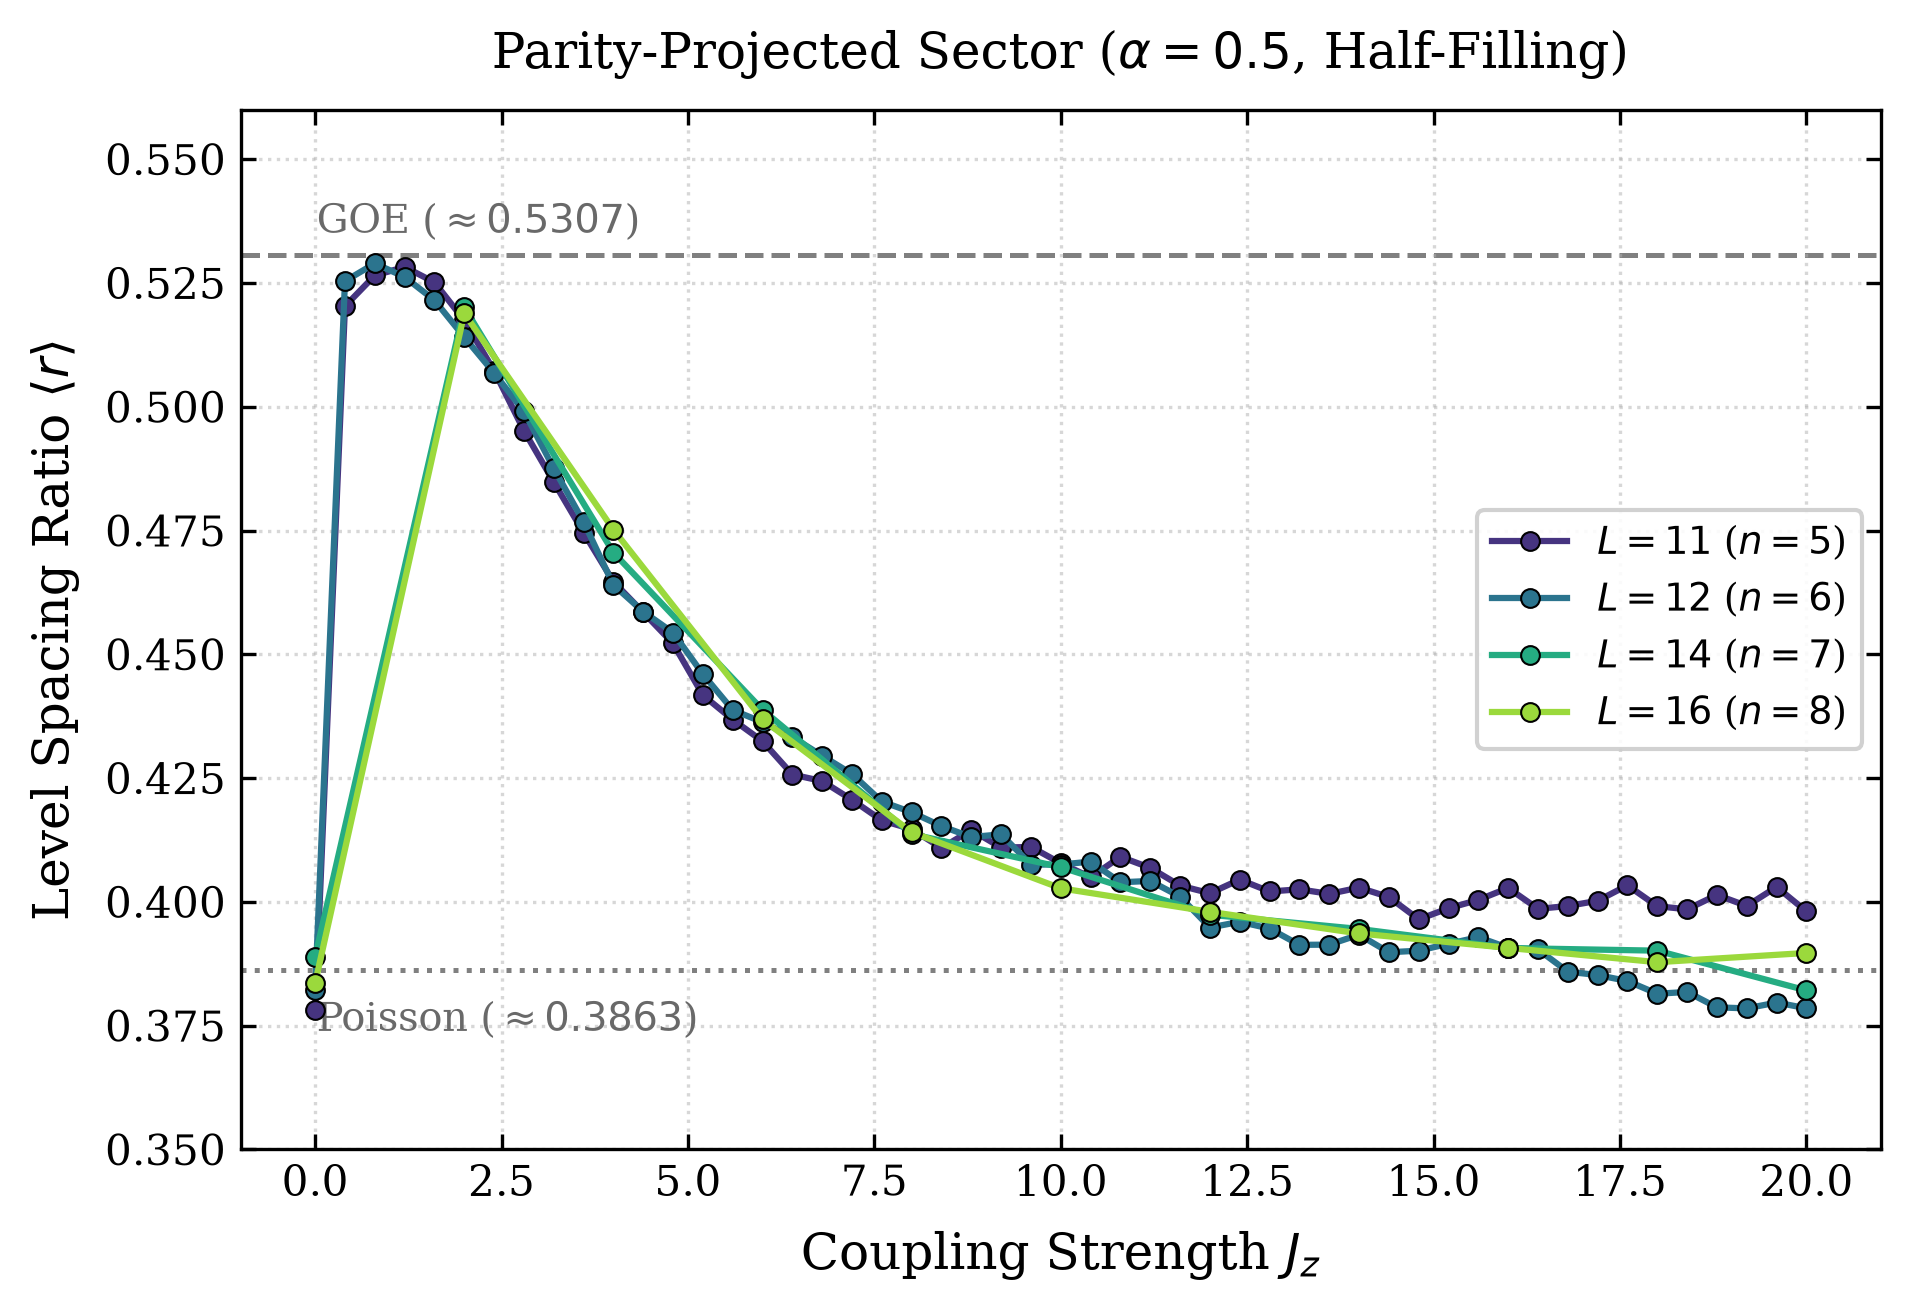

In [90]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# Set publication typography & axis style (Journal Style)
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.titlesize": 13,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

fig, ax = plt.subplots(figsize=(6.5, 4.5), dpi=300)

# Colors mapped dynamically to system sizes L
L_values = sorted(data_dict.keys())
colors = cm.viridis(np.linspace(0.15, 0.85, len(L_values)))

# ------------------------------------------------------------
# 1. Asymptotic Reference Lines (GOE vs Poisson)
# ------------------------------------------------------------
ax.axhline(0.5307, linestyle="--", color="gray", linewidth=1.2, zorder=1)
ax.axhline(0.3863, linestyle=":", color="gray", linewidth=1.2, zorder=1)

# Annotate reference limits directly on plot to clean up the legend
ax.text(
    ax.get_xlim()[0] if ax.get_xlim()[0] != 0 else 0.02, 
    0.533, 
    r"GOE ($\approx 0.5307$)", 
    color="dimgray", 
    fontsize=9.5, 
    va="bottom"
)
ax.text(
    ax.get_xlim()[0] if ax.get_xlim()[0] != 0 else 0.02, 
    0.380, 
    r"Poisson ($\approx 0.3863$)", 
    color="dimgray", 
    fontsize=9.5, 
    va="top"
)

# ------------------------------------------------------------
# 2. Main Data Traces
# ------------------------------------------------------------
for i, L in enumerate(L_values):
    sub = data_dict[L]
    n_up = L // 2
    
    ax.plot(
        sub["Jz"],
        sub["r_mean"],
        marker="o",
        markersize=4.5,
        markerfacecolor=colors[i],
        markeredgecolor="black",
        markeredgewidth=0.5,
        linewidth=1.5,
        color=colors[i],
        label=rf"$L = {L}$ ($n={n_up}$)",
        zorder=3 + i
    )

# ------------------------------------------------------------
# 3. Axes, Labels, and Legend
# ------------------------------------------------------------
ax.set_xlabel(r"Coupling Strength $J_z$", labelpad=6)
ax.set_ylabel(r"Level Spacing Ratio $\langle r \rangle$", labelpad=6)
ax.set_title(
    rf"Parity-Projected Sector ($\alpha = {alpha}$, Half-Filling)", 
    pad=10
)

# Set logical y-limits covering Poisson to GOE with margin
ax.set_ylim(0.35, 0.56)

ax.grid(True, linestyle=":", alpha=0.5, zorder=0)
ax.legend(frameon=True, facecolor="white", framealpha=0.9, loc="best")

plt.tight_layout()
plt.savefig("plt/r_vs_Jz_sectors_L11.pdf", dpi=300, bbox_inches="tight")
plt.show()

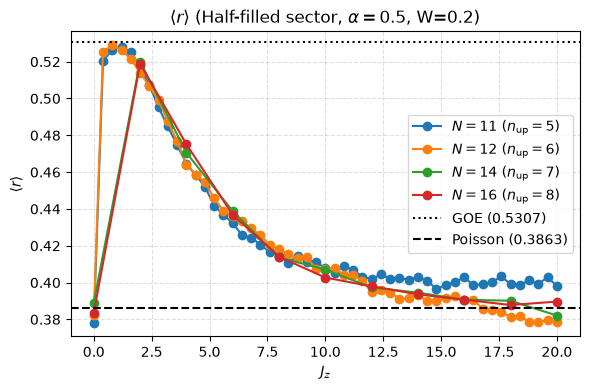

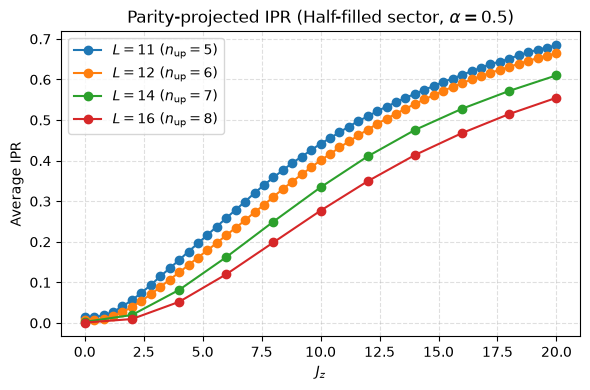

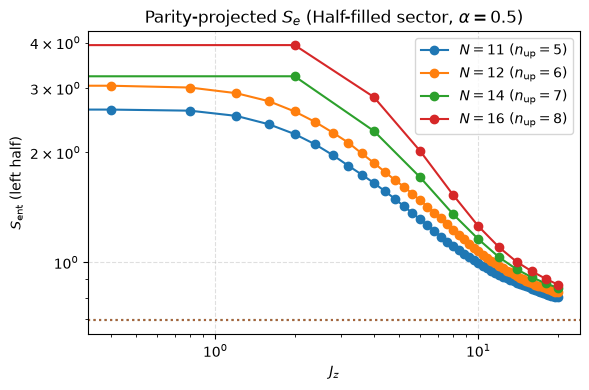

In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [11, 12, 14, 16]
alpha = 0.5
W = 0.2

# Pre-load data into dictionaries for half-filling sectors
data_dict = {}
page_dict = {}

for L in L_values:
    n_up = L // 2  # Dynamic half-filling sector for each L

    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter for n_up = L // 2
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["Jz"],
        sub["r_mean"],
        marker="o",
        label=rf"$N={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"$\langle r\rangle$ (Half-filled sector, $\alpha={alpha}$, W=0.2)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("plt/r_vs_Jz_sectors_L11.pdf")
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["Jz"],
        sub["ipr_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(
    rf"Parity-projected IPR (Half-filled sector, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    (line,) = plt.loglog(
        sub["Jz"],
        sub["S_mean"],
        marker="o",
        label=rf"$N={L}\ (n_{{\rm up}}={n_up})$",
    )

    # Plot Page estimate reference line corresponding to this L's half-filled sector
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected $S_e$ (Half-filled sector, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

#### W=0, b=2

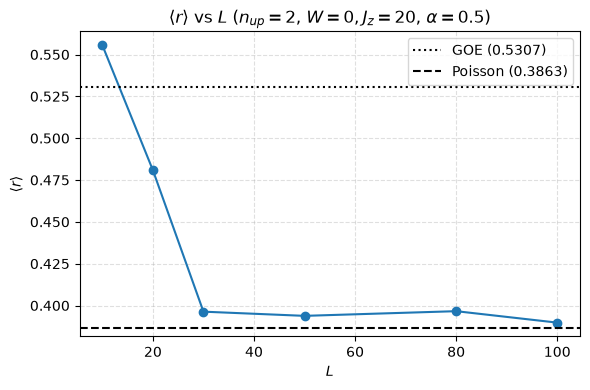

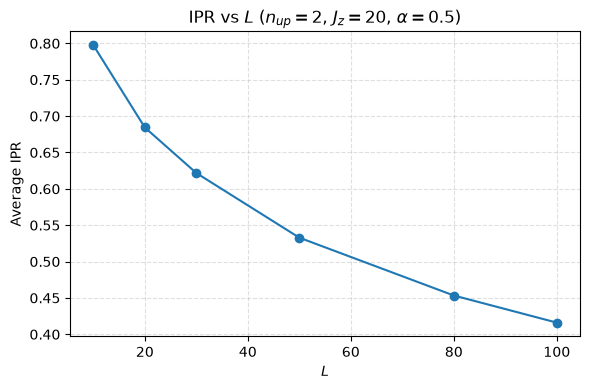

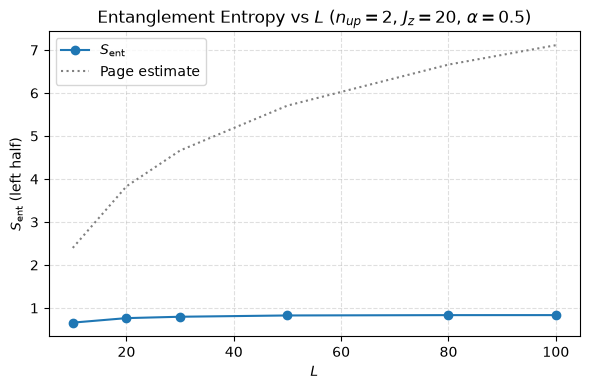

In [2]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL/b2sector"
L_values = [10, 20, 30, 50, 80, 100]
alpha = 0.5
W = 0.0
n_up = 2
Jz_target = 20  # the single Jz value used in the sweep

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
rows = []
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        sub = df[(df["n_up"] == n_up) & (df["Jz"] == Jz_target)]
        if not sub.empty:
            rows.append(sub.iloc[0])

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]

data = pd.DataFrame(rows).sort_values("L")

# ------------------------------------------------------------
# 1. <r> vs L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(data["L"], data["r_mean"], marker="o")
plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$L$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"$\langle r\rangle$ vs $L$ ($n_{{up}}={n_up}$, $W=0, J_z={Jz_target}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. IPR vs L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(data["L"], data["ipr_mean"], marker="o")
plt.xlabel(r"$L$")
plt.ylabel("Average IPR")
plt.title(rf"IPR vs $L$ ($n_{{up}}={n_up}$, $J_z={Jz_target}$, $\alpha={alpha}$)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Entanglement entropy vs L, with Page-value reference
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(data["L"], data["S_mean"], marker="o", label=r"$S_{\rm ent}$")

page_L = [L for L in L_values if L in page_dict]
page_S = [page_dict[L] for L in page_L]
if page_L:
    plt.plot(page_L, page_S, linestyle=":", color="gray", label="Page estimate")

plt.xlabel(r"$L$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy vs $L$ ($n_{{up}}={n_up}$, $J_z={Jz_target}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

#### W=0, b=2,3

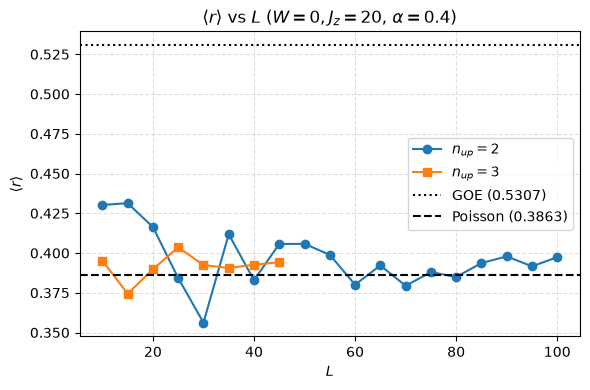

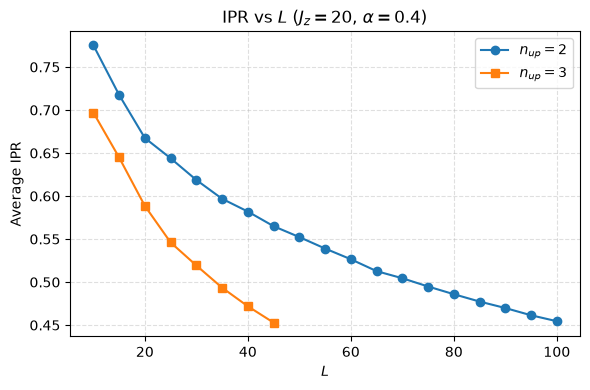

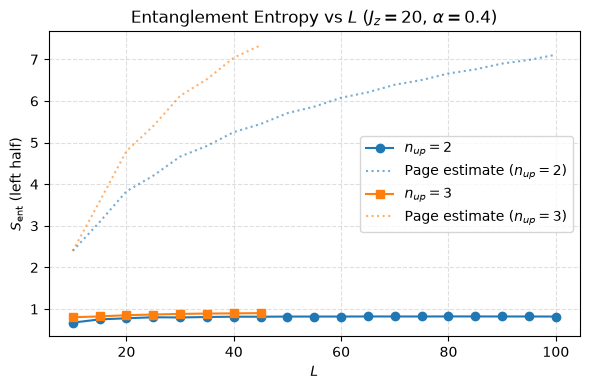

In [8]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
sectors = {
    2: {"dir": "MBL/b2sector", "L_values": list(range(10, 101, 5))},
    3: {"dir": "MBL/b3sector", "L_values": [10, 15, 20, 25, 30, 35, 40, 45]},
}
alpha = 0.4
W = 0.0
Jz_target = 20  # the single Jz value used in the sweep

# ------------------------------------------------------------
# Load data for both sectors
# ------------------------------------------------------------
sector_data = {}   # n_up -> DataFrame of sweep rows
sector_pages = {}  # n_up -> {L: S_max_estimate}

for n_up, cfg in sectors.items():
    output_dir = cfg["dir"]
    L_values = cfg["L_values"]

    rows = []
    page_dict = {}

    for L in L_values:
        sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
        page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

        if os.path.exists(sweep_file):
            df = pd.read_csv(sweep_file)
            sub = df[(df["n_up"] == n_up) & (df["Jz"] == Jz_target)].copy()
            if not sub.empty:
                sub["L"] = L
                rows.append(sub.iloc[0])
            else:
                print(f"[n_up={n_up}] No matching row for L={L}")
        else:
            print(f"[n_up={n_up}] Missing file: {sweep_file}")

        if os.path.exists(page_file):
            page_df = pd.read_csv(page_file).set_index("n_up")
            if n_up in page_df.index:
                page_dict[L] = page_df.loc[n_up, "S_max_estimate"]

    sector_data[n_up] = pd.DataFrame(rows).sort_values("L") if rows else pd.DataFrame()
    sector_pages[n_up] = page_dict

# Style per sector so the two curves are visually distinct
styles = {2: {"color": "tab:blue", "marker": "o", "label": r"$n_{up}=2$"},
          3: {"color": "tab:orange", "marker": "s", "label": r"$n_{up}=3$"}}

# ------------------------------------------------------------
# 1. <r> vs L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
for n_up, data in sector_data.items():
    if not data.empty:
        plt.plot(data["L"], data["r_mean"], marker=styles[n_up]["marker"],
                  color=styles[n_up]["color"], label=styles[n_up]["label"])
plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$L$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"$\langle r\rangle$ vs $L$ ($W=0, J_z={Jz_target}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("plt/W0b2b3LsweepErgodicity.pdf")
plt.show()

# ------------------------------------------------------------
# 2. IPR vs L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
for n_up, data in sector_data.items():
    if not data.empty:
        plt.plot(data["L"], data["ipr_mean"], marker=styles[n_up]["marker"],
                  color=styles[n_up]["color"], label=styles[n_up]["label"])
plt.xlabel(r"$L$")
plt.ylabel("Average IPR")
plt.title(rf"IPR vs $L$ ($J_z={Jz_target}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("plt/W0b2b3LsweepIPR.pdf")
plt.show()

# ------------------------------------------------------------
# 3. Entanglement entropy vs L, with Page-value reference
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
for n_up, data in sector_data.items():
    if not data.empty:
        plt.plot(data["L"], data["S_mean"], marker=styles[n_up]["marker"],
                  color=styles[n_up]["color"], label=styles[n_up]["label"])

    page_dict = sector_pages[n_up]
    page_L = sorted(page_dict.keys())
    page_S = [page_dict[L] for L in page_L]
    if page_L:
        plt.plot(page_L, page_S, linestyle=":", color=styles[n_up]["color"], alpha=0.6,
                  label=f"Page estimate ({styles[n_up]['label']})")

plt.xlabel(r"$L$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy vs $L$ ($J_z={Jz_target}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

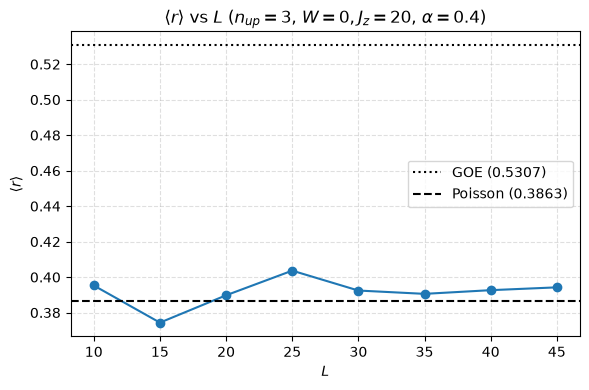

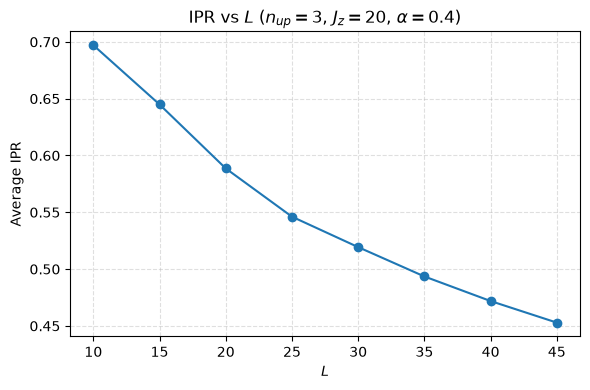

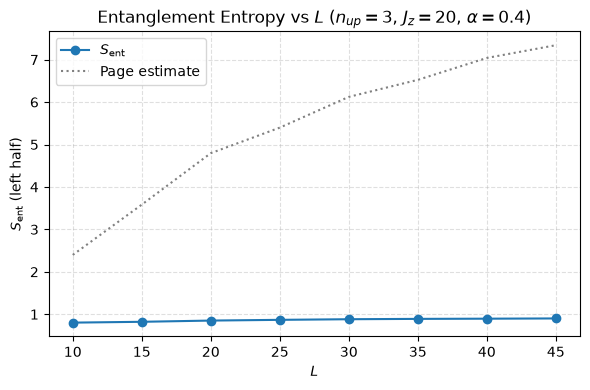

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir2 = "MBL/b2sector"
output_dir3 = "MBL/b3sector"
L_values2 =list(range(10, 101, 5))
L_values3 = [10, 15, 20, 25, 30, 35, 40, 45]
alpha = 0.4
W = 0.0
n_up = 3
Jz_target = 20  # the single Jz value used in the sweep

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
rows = []
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        sub = df[(df["n_up"] == n_up) & (df["Jz"] == Jz_target)]
        if not sub.empty:
            rows.append(sub.iloc[0])

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]

data = pd.DataFrame(rows).sort_values("L")

# ------------------------------------------------------------
# 1. <r> vs L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(data["L"], data["r_mean"], marker="o")
plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$L$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"$\langle r\rangle$ vs $L$ ($n_{{up}}={n_up}$, $W=0, J_z={Jz_target}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. IPR vs L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(data["L"], data["ipr_mean"], marker="o")
plt.xlabel(r"$L$")
plt.ylabel("Average IPR")
plt.title(rf"IPR vs $L$ ($n_{{up}}={n_up}$, $J_z={Jz_target}$, $\alpha={alpha}$)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Entanglement entropy vs L, with Page-value reference
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(data["L"], data["S_mean"], marker="o", label=r"$S_{\rm ent}$")

page_L = [L for L in L_values if L in page_dict]
page_S = [page_dict[L] for L in page_L]
if page_L:
    plt.plot(page_L, page_S, linestyle=":", color="gray", label="Page estimate")

plt.xlabel(r"$L$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Entanglement Entropy vs $L$ ($n_{{up}}={n_up}$, $J_z={Jz_target}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

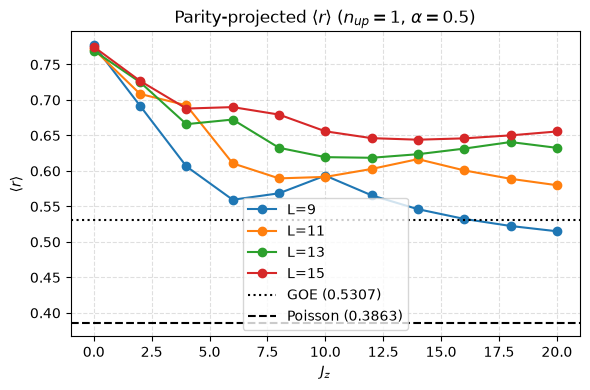

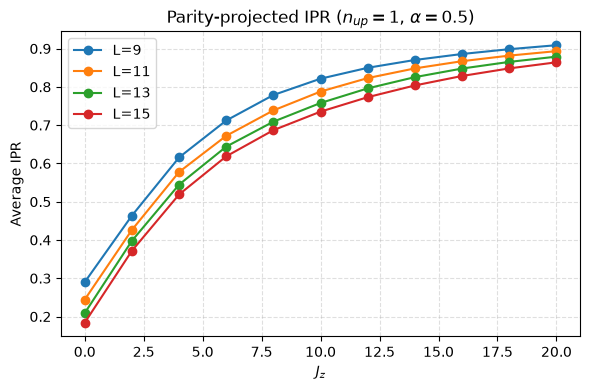

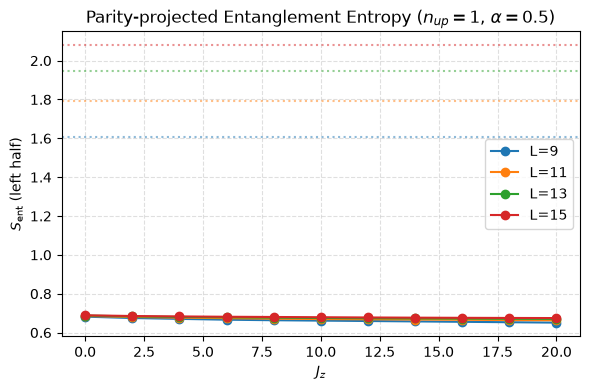

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [9, 11, 13, 15]
alpha = 0.5
W = 0.0
n_up = 1

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

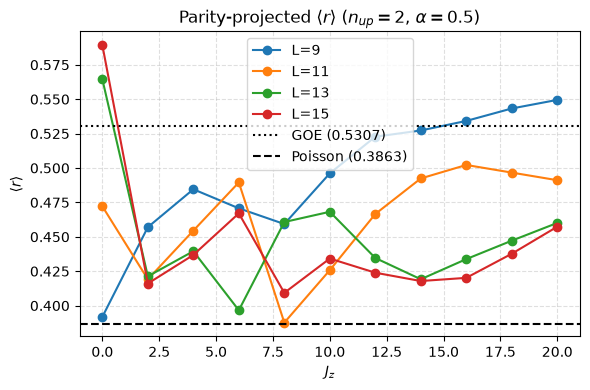

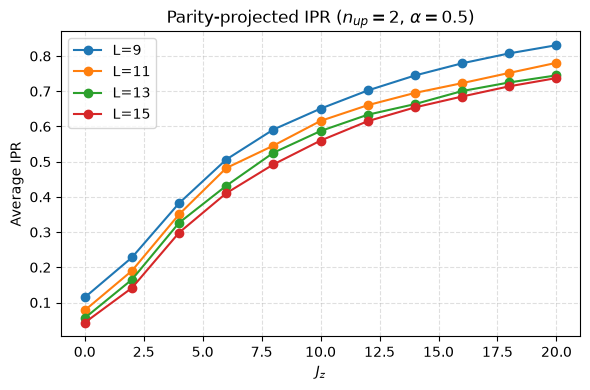

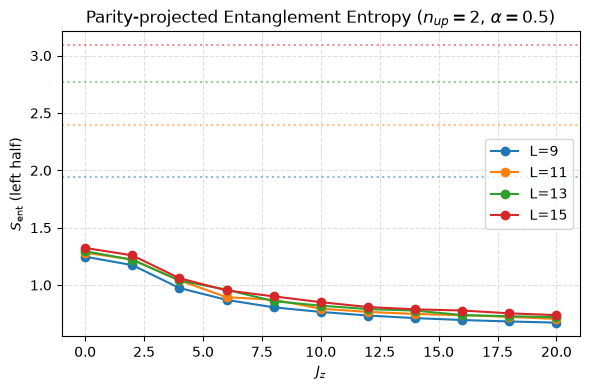

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [9, 11, 13, 15]
alpha = 0.5
W = 0.0
n_up = 2

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

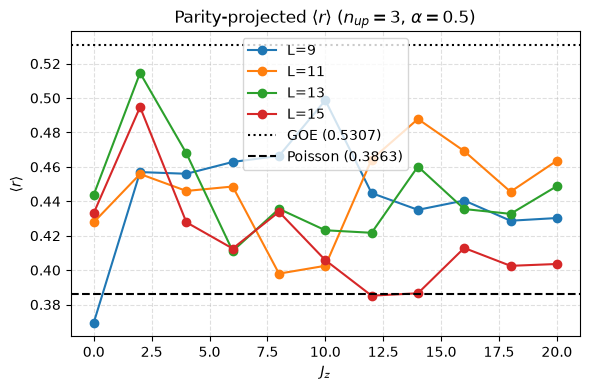

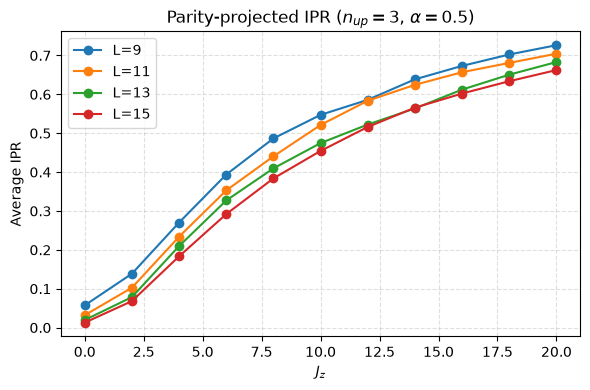

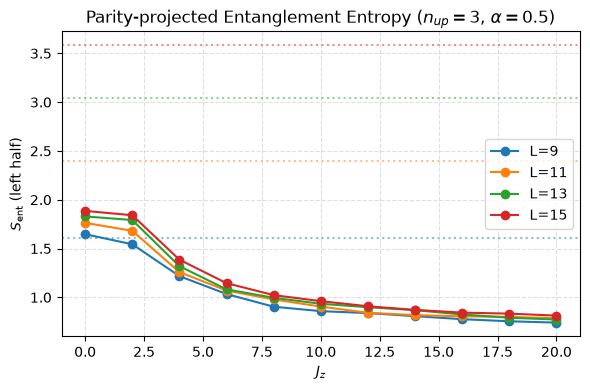

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [9, 11, 13, 15]
alpha = 0.5
W = 0.0
n_up = 3

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

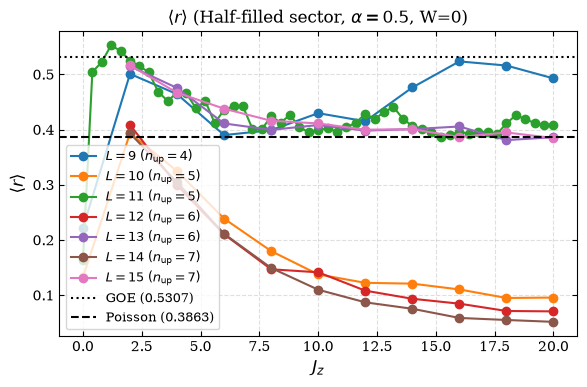

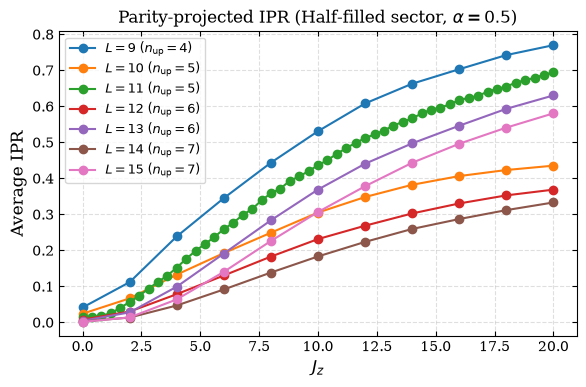

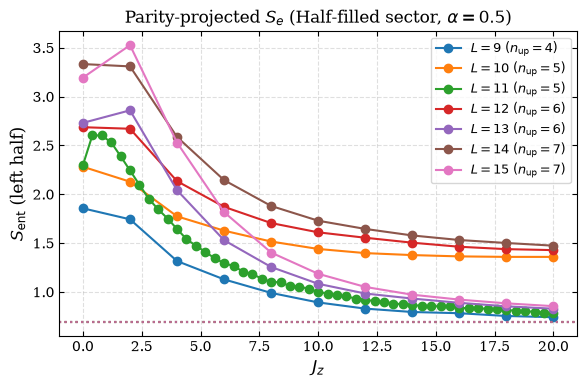

In [93]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [9, 10, 11, 12, 13, 14, 15]
alpha = 0.5
W = 0.0

# Pre-load data into dictionaries for half-filling sectors
data_dict = {}
page_dict = {}

for L in L_values:
    n_up = L // 2  # Dynamic half-filling sector for each L

    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter for n_up = L // 2
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["Jz"],
        sub["r_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"$\langle r\rangle$ (Half-filled sector, $\alpha={alpha}$, W=0)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("plt/r_vs_Jz_scaling_evenodd.pdf")
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["Jz"],
        sub["ipr_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(
    rf"Parity-projected IPR (Half-filled sector, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    (line,) = plt.plot(
        sub["Jz"],
        sub["S_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

    # Plot Page estimate reference line corresponding to this L's half-filled sector
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected $S_e$ (Half-filled sector, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

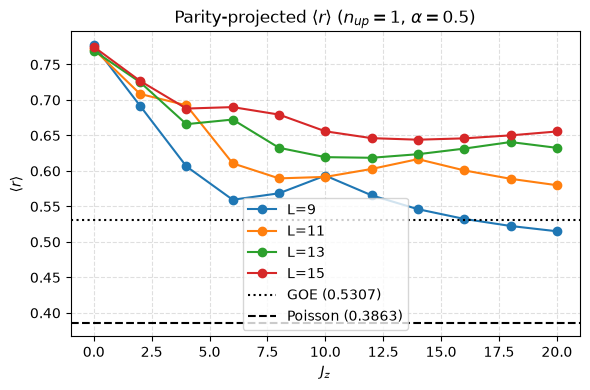

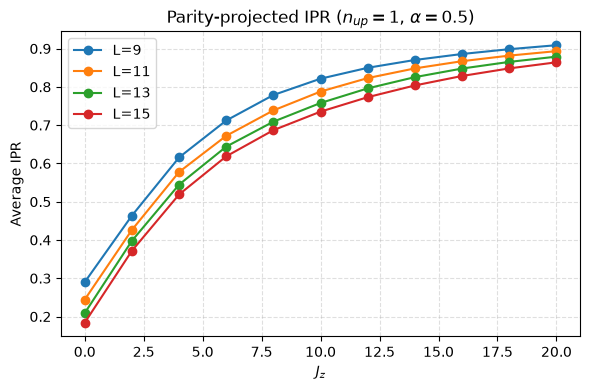

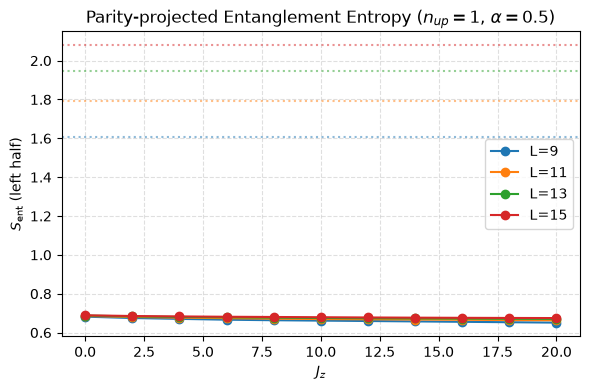

In [17]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [9, 11, 13, 15]
alpha = 0.5
W = 0.0
n_up = 1

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

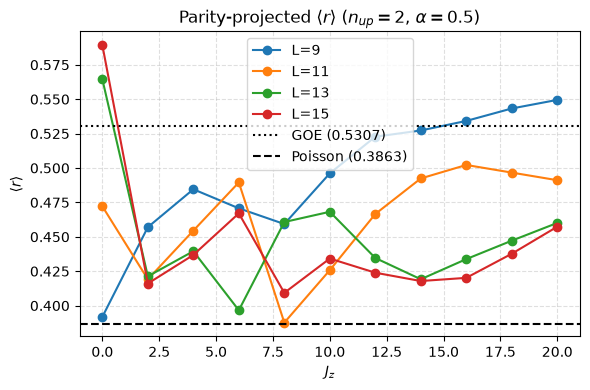

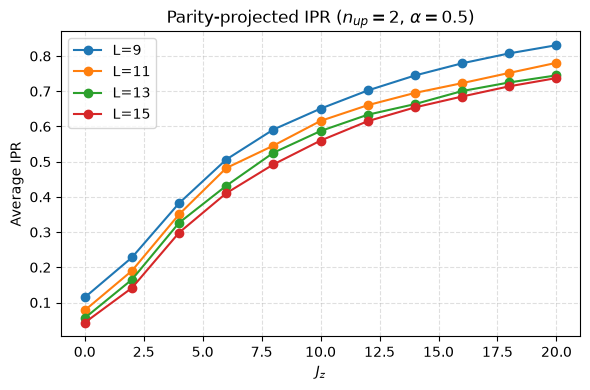

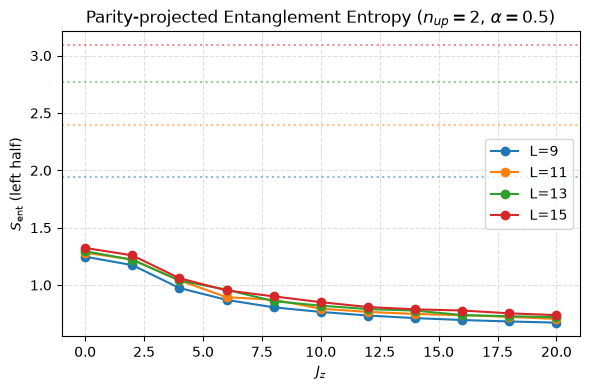

In [18]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [9, 11, 13, 15]
alpha = 0.5
W = 0.0
n_up = 2

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

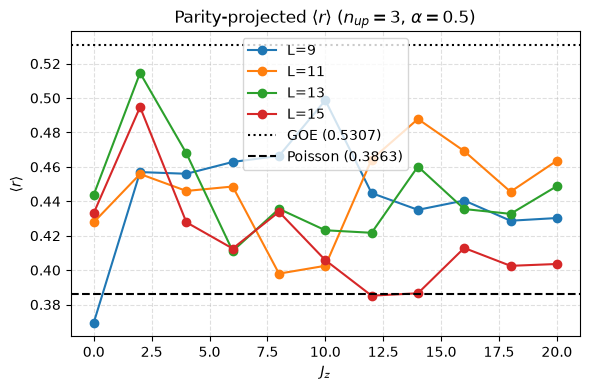

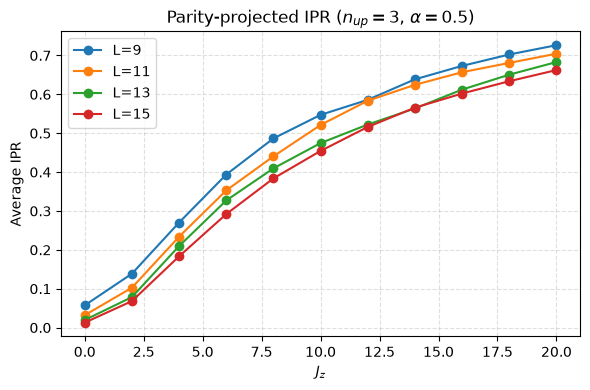

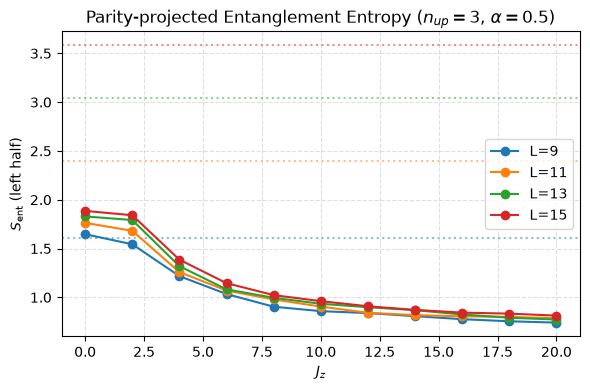

In [19]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [9, 11, 13, 15]
alpha = 0.5
W = 0.0
n_up = 3

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

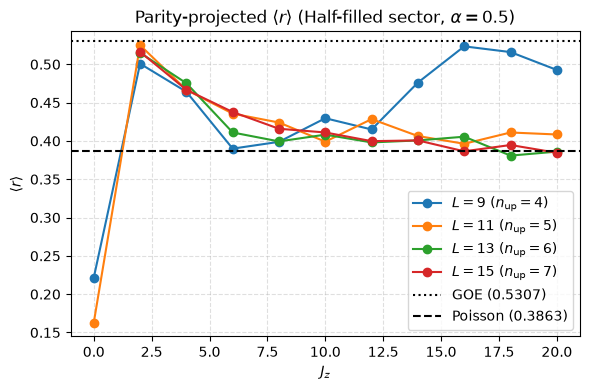

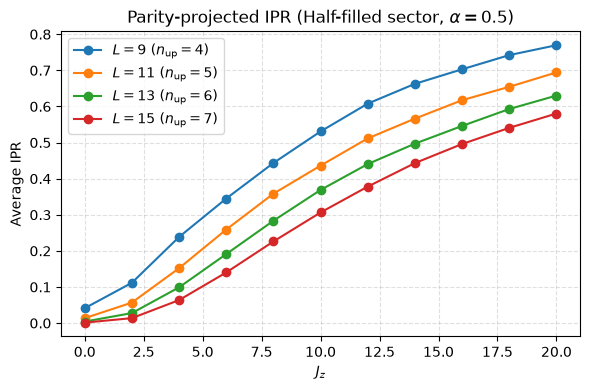

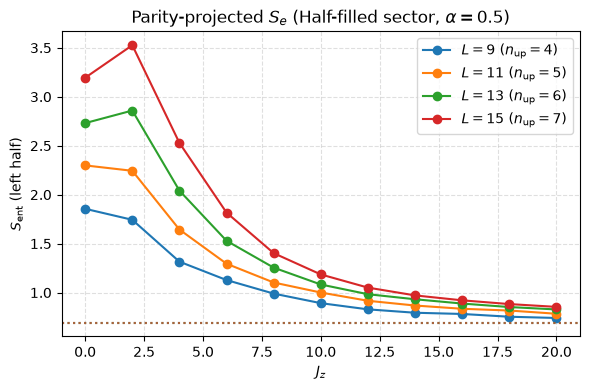

In [20]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [9, 11, 13, 15]
alpha = 0.5
W = 0.0

# Pre-load data into dictionaries for half-filling sectors
data_dict = {}
page_dict = {}

for L in L_values:
    n_up = L // 2  # Dynamic half-filling sector for each L

    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter for n_up = L // 2
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["Jz"],
        sub["r_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ (Half-filled sector, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["Jz"],
        sub["ipr_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(
    rf"Parity-projected IPR (Half-filled sector, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    (line,) = plt.plot(
        sub["Jz"],
        sub["S_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

    # Plot Page estimate reference line corresponding to this L's half-filled sector
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected $S_e$ (Half-filled sector, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

#### W=0.05

### $\alpha$ sweep

#### Half-filled case

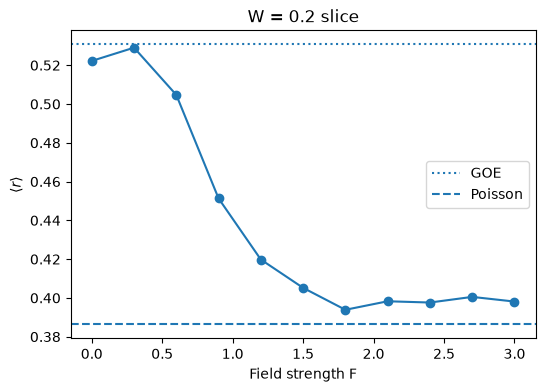

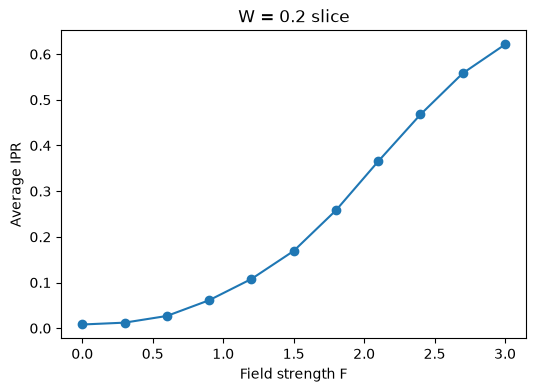

In [ ]:
# ============================================================
# Imports
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations
from scipy.linalg import eigh


# ============================================================
# Basis: half-filled sector
# ============================================================

def half_filled_basis(L):
    """
    Generate all spin configurations with L/2 up spins.
    
    State convention:
    1 = spin up
    0 = spin down
    """

    basis = []

    for ups in combinations(range(L), L//2):

        state = [0]*L

        for i in ups:
            state[i] = 1

        basis.append(tuple(state))

    return basis



def basis_index(basis):

    return {
        state:i for i,state in enumerate(basis)
    }



# ============================================================
# Heisenberg Hamiltonian
# ============================================================
def build_heisenberg(L, J0=1.0, Jz=1.0, F=0.0, h=None):
    """
    Anisotropic Heisenberg (XXZ) Hamiltonian with tilt:

    H = sum_j [ J0 (SxSx + SySy) + Jz SzSz ]_{j,j+1}
        + sum_j F*j*Sz_j
        + sum_j h_j*Sz_j

    Restricted to half-filled sector.

    Parameters
    ----------
    L  : system size
    J0 : XY (flip-flop) coupling
    Jz : Ising (ZZ) coupling
    F  : linear tilt field strength
    h  : array of random on-site fields (optional)

    Returns
    -------
    H, basis
    """

    basis = half_filled_basis(L)
    index = basis_index(basis)

    dim = len(basis)

    H = np.zeros((dim,dim),dtype=float)


    for n,state in enumerate(basis):


        # -----------------------------
        # on-site Sz terms: tilt + random field
        # -----------------------------

        for i in range(L):

            sz = 0.5 if state[i]==1 else -0.5

            # linear tilt field F*j*Sz_j
            H[n,n] += F*i*sz

            # random field h_j*Sz_j
            if h is not None:
                H[n,n] += h[i]*sz



        # -----------------------------
        # nearest-neighbor XXZ terms
        # -----------------------------

        for i in range(L-1):

            si = 1 if state[i]==1 else -1
            sj = 1 if state[i+1]==1 else -1


            # Jz SzSz contribution

            H[n,n] += Jz*0.25*si*sj



            # J0 (SxSx + SySy)
            # flips neighboring opposite spins

            if state[i] != state[i+1]:


                new_state = list(state)

                new_state[i],new_state[i+1] = (
                    new_state[i+1],
                    new_state[i]
                )

                new_state = tuple(new_state)

                m = index[new_state]


                H[m,n] += J0*0.5


    return H,basis



# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H):

    evals,evecs = eigh(H)

    return evals,evecs



# ============================================================
# Select middle of spectrum
# ============================================================

def middle_spectrum(evals,evecs,frac=0.2):
    """
    Keep fraction of states around the middle energy.
    """

    N=len(evals)

    start=int(N*(0.5-frac/2))
    end  =int(N*(0.5+frac/2))


    return evals[start:end], evecs[:,start:end]



# ============================================================
# Level statistics
# ============================================================

def level_spacing_ratio(evals):

    evals=np.sort(evals)

    spacings=np.diff(evals)


    r=[]

    for i in range(len(spacings)-1):

        r.append(
            min(spacings[i],spacings[i+1]) /
            max(spacings[i],spacings[i+1])
        )


    return np.mean(r)



# ============================================================
# Inverse participation ratio
# ============================================================

def compute_IPR(evecs):
    """
    IPR = sum_i |psi_i|^4
    """

    ipr=[]


    for n in range(evecs.shape[1]):

        psi=evecs[:,n]

        ipr.append(
            np.sum(np.abs(psi)**4)
        )


    return np.array(ipr)



# ============================================================
# Single disorder realization
# ============================================================

def analyze_realization(L,W,J0=1.0,Jz=1.0,F=0.0,frac=0.2):
    """
    One disorder realization.

    h_i uniform[-W,W]
    """

    h=np.random.uniform(-W,W,L)


    H,basis = build_heisenberg(
        L=L,
        J0=J0,
        Jz=Jz,
        F=F,
        h=h
    )


    evals,evecs = diagonalize(H)


    evals_mid,evecs_mid = middle_spectrum(
        evals,
        evecs,
        frac
    )


    r = level_spacing_ratio(evals_mid)

    ipr = np.mean(
        compute_IPR(evecs_mid)
    )


    return r,ipr

# ============================================================
# Disorder averaging
# ============================================================

def disorder_average(
        L,
        W,
        realizations=50,
        J0=1.0,
        Jz=1.0,
        F=0.0,
        frac=1):


    r_values=[]
    ipr_values=[]


    for _ in range(realizations):

        r,ipr = analyze_realization(
            L=L,
            W=W,
            J0=J0,
            Jz=Jz,
            F=F,
            frac=frac
        )

        r_values.append(r)
        ipr_values.append(ipr)


    return (
        np.mean(r_values),
        np.std(r_values),
        np.mean(ipr_values),
        np.std(ipr_values)
    )



# ============================================================
# Example: reproduce r statistics vs disorder
# ============================================================

L=11

# W_values=np.linspace(0,7,21)
W_values=[0.2]


r_results=[]
ipr_results=[]


for W in W_values:

    r_mean,r_std,ipr_mean,ipr_std = disorder_average(
        L=L,
        W=W,
        realizations=120,
        J0=1,
        Jz=1,
        F=0.5,
        frac=1
    )


    r_results.append(r_mean)
    ipr_results.append(ipr_mean)


# ============================================================
# F sweep at fixed W=0.2
# ============================================================

F_values = np.linspace(0, 3, 11)

r_results_F = []
ipr_results_F = []

for F in F_values:

    r_mean, r_std, ipr_mean, ipr_std = disorder_average(
        L=L,
        W=0.2,
        realizations=120,
        J0=1,
        Jz=1,
        F=F,
        frac=0.5
    )

    r_results_F.append(r_mean)
    ipr_results_F.append(ipr_mean)


plt.figure(figsize=(6,4))
plt.plot(F_values, r_results_F, marker="o")
plt.axhline(0.5307, linestyle=":", label="GOE")
plt.axhline(0.3863, linestyle="--", label="Poisson")
plt.xlabel("Field strength F")
plt.ylabel(r"$\langle r\rangle$")
plt.title("W = 0.2 slice")
plt.legend()
plt.show()


plt.figure(figsize=(6,4))
plt.plot(F_values, ipr_results_F, marker="o")
plt.xlabel("Field strength F")
plt.ylabel("Average IPR")
plt.title("W = 0.2 slice")
plt.show()

#### Single excitation case

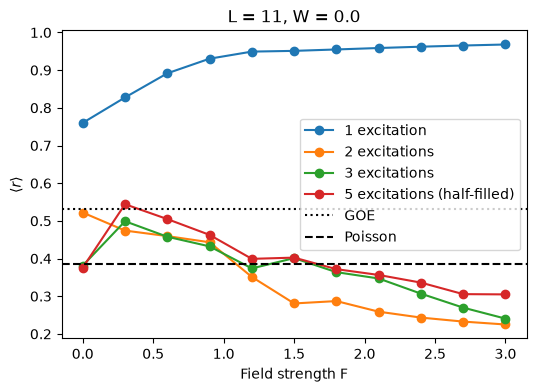

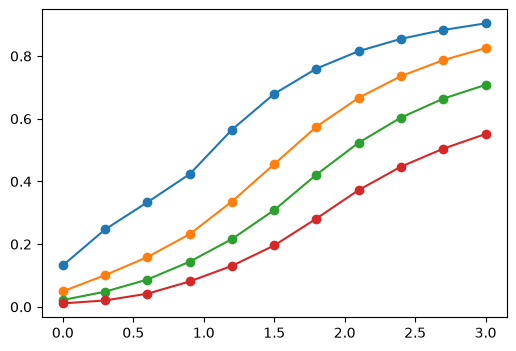

In [ ]:
# ============================================================
# Imports
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations
from scipy.linalg import eigh


# ============================================================
# Basis: fixed number of excitations (up spins)
# ============================================================

def fixed_excitation_basis(L, n_up):
    """
    Generate all spin configurations with n_up up spins.

    n_up = L//2  -> half-filled sector
    n_up = 1     -> single-excitation sector

    State convention:
    1 = spin up
    0 = spin down
    """

    basis = []

    for ups in combinations(range(L), n_up):

        state = [0]*L

        for i in ups:
            state[i] = 1

        basis.append(tuple(state))

    return basis



def basis_index(basis):

    return {
        state:i for i,state in enumerate(basis)
    }



# ============================================================
# Heisenberg Hamiltonian (generalized to n_up excitations)
# ============================================================
def build_heisenberg(L, n_up=None, J0=1.0, Jz=1.0, F=0.0, h=None):
    """
    Anisotropic Heisenberg (XXZ) Hamiltonian with tilt:

    H = sum_j [ J0 (SxSx + SySy) + Jz SzSz ]_{j,j+1}
        + sum_j F*j*Sz_j
        + sum_j h_j*Sz_j

    Restricted to a fixed n_up (excitation number) sector.

    Parameters
    ----------
    L    : system size
    n_up : number of up spins (excitations).
           Default: L//2 (half-filled sector)
           Set n_up=1 for the single-excitation sector.
    J0   : XY (flip-flop) coupling
    Jz   : Ising (ZZ) coupling
    F    : linear tilt field strength
    h    : array of random on-site fields (optional)

    Returns
    -------
    H, basis
    """

    if n_up is None:
        n_up = L // 2

    basis = fixed_excitation_basis(L, n_up)
    index = basis_index(basis)

    dim = len(basis)

    H = np.zeros((dim,dim),dtype=float)


    for n,state in enumerate(basis):


        # -----------------------------
        # on-site Sz terms: tilt + random field
        # -----------------------------

        for i in range(L):

            sz = 0.5 if state[i]==1 else -0.5

            # linear tilt field F*j*Sz_j
            H[n,n] += F*i*sz

            # random field h_j*Sz_j
            if h is not None:
                H[n,n] += h[i]*sz



        # -----------------------------
        # nearest-neighbor XXZ terms
        # -----------------------------

        for i in range(L-1):

            si = 1 if state[i]==1 else -1
            sj = 1 if state[i+1]==1 else -1


            # Jz SzSz contribution

            H[n,n] += Jz*0.25*si*sj



            # J0 (SxSx + SySy)
            # flips neighboring opposite spins

            if state[i] != state[i+1]:


                new_state = list(state)

                new_state[i],new_state[i+1] = (
                    new_state[i+1],
                    new_state[i]
                )

                new_state = tuple(new_state)

                m = index[new_state]


                H[m,n] += J0*0.5


    return H,basis



# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H):

    evals,evecs = eigh(H)

    return evals,evecs



# ============================================================
# Select middle of spectrum
# ============================================================

def middle_spectrum(evals,evecs,frac=0.2):
    """
    Keep fraction of states around the middle energy.
    """

    N=len(evals)

    start=int(N*(0.5-frac/2))
    end  =int(N*(0.5+frac/2))


    return evals[start:end], evecs[:,start:end]



# ============================================================
# Level statistics
# ============================================================

def level_spacing_ratio(evals):

    evals=np.sort(evals)

    spacings=np.diff(evals)


    r=[]

    for i in range(len(spacings)-1):

        r.append(
            min(spacings[i],spacings[i+1]) /
            max(spacings[i],spacings[i+1])
        )


    return np.mean(r)



# ============================================================
# Inverse participation ratio
# ============================================================

def compute_IPR(evecs):
    """
    IPR = sum_i |psi_i|^4
    """

    ipr=[]


    for n in range(evecs.shape[1]):

        psi=evecs[:,n]

        ipr.append(
            np.sum(np.abs(psi)**4)
        )


    return np.array(ipr)



# ============================================================
# Single disorder realization
# ============================================================

def analyze_realization(L,W,n_up=None,J0=1.0,Jz=1.0,F=0.0,frac=0.2):
    """
    One disorder realization.

    h_i uniform[-W,W]

    n_up : excitation number sector (None -> half-filled)
    """

    h=np.random.uniform(-W,W,L)


    H,basis = build_heisenberg(
        L=L,
        n_up=n_up,
        J0=J0,
        Jz=Jz,
        F=F,
        h=h
    )


    evals,evecs = diagonalize(H)


    evals_mid,evecs_mid = middle_spectrum(
        evals,
        evecs,
        frac
    )


    # Single-excitation sector has dim = L, which can be too
    # small for a meaningful gap-ratio average once you also
    # restrict to the "middle" — guard against too-few levels.
    if len(evals_mid) < 3:
        r = np.nan
    else:
        r = level_spacing_ratio(evals_mid)

    ipr = np.mean(
        compute_IPR(evecs_mid)
    )


    return r,ipr

# ============================================================
# Disorder averaging
# ============================================================

def disorder_average(
        L,
        W,
        n_up=None,
        realizations=50,
        J0=1.0,
        Jz=1.0,
        F=0.0,
        frac=1):


    r_values=[]
    ipr_values=[]


    for _ in range(realizations):

        r,ipr = analyze_realization(
            L=L,
            W=W,
            n_up=n_up,
            J0=J0,
            Jz=Jz,
            F=F,
            frac=frac
        )

        r_values.append(r)
        ipr_values.append(ipr)


    return (
        np.nanmean(r_values),
        np.nanstd(r_values),
        np.mean(ipr_values),
        np.std(ipr_values)
    )


# ============================================================
# F sweep across multiple excitation-number sectors, fixed L
# ============================================================

L = 11
F_values = np.linspace(0, 3, 11)

# Sectors to compare: 1, 2, 3 excitations, and half-filling
n_up_values = [1, 2, 3, L // 2]

results = {}   # n_up -> dict with 'r' and 'ipr' lists

for n_up in n_up_values:

    r_results = []
    ipr_results = []

    for F in F_values:

        r_mean, r_std, ipr_mean, ipr_std = disorder_average(
            L=L, W=0.0, n_up=n_up,
            realizations=1,
            J0=1, Jz=1, F=F, frac=1
        )

        r_results.append(r_mean)
        ipr_results.append(ipr_mean)

    results[n_up] = {
        "r": r_results,
        "ipr": ipr_results
    }


# ------------------------------------------------------------
# Plot <r> for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(6,4))

for n_up in n_up_values:
    label = f"{n_up} excitation" if n_up == 1 else f"{n_up} excitations"
    if n_up == L // 2:
        label += " (half-filled)"
    plt.plot(F_values, results[n_up]["r"], marker="o", label=label)

plt.axhline(0.5307, linestyle=":", color="k", label="GOE")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson")
plt.xlabel("Field strength F")
plt.ylabel(r"$\langle r\rangle$")
plt.title(f"L = {L}, W = 0.0")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot IPR for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(6,4))

for n_up in n_up_values:
    label = f"{n_up} excitation" if n_up == 1 else f"{n_up} excitations"
    if n_up == L // 2:
        label += " (half-filled)"
    plt.plot(F_values, results[n_up]["ipr"], marker="o", label=label)


# Lea's Model